### **Building a Deep Learning Regression Model**

In [1]:
import logging
import os
from datetime import datetime

os.makedirs("logs", exist_ok=True)
logger = logging.getLogger("DLModel-EDA")
logger.setLevel(logging.INFO)

In [2]:
if not logger.handlers:

    # Log file with timestamp
    log_file = f"logs/dlmodel_{datetime.now():%Y%m%d}.log"

    # File handler
    file_handler = logging.FileHandler(log_file, mode="a", encoding="utf-8")
    file_handler.setLevel(logging.INFO)

    # Console handler
    console_handler = logging.StreamHandler()
    console_handler.setLevel(logging.INFO)

    # Log format
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s",
        datefmt="%Y-%m-%d %H:%M:%S"
    )

    file_handler.setFormatter(formatter)
    console_handler.setFormatter(formatter)

    logger.addHandler(file_handler)
    logger.addHandler(console_handler)

logger.info("=" * 70)
logger.info("Deep Learning Model - DL LOGGING STARTED")
logger.info("=" * 70)


2026-11-15 15:50:40 | INFO | ======================================================================
2026-11-15 15:50:40 | INFO | Deep Learning Model - DL LOGGING STARTED
2026-11-15 15:50:40 | INFO | ======================================================================


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Time series analysis
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
train_df = pd.read_csv(
    'data/train_merged.csv',
    parse_dates=['Date']
)

test_df = pd.read_csv(
    'data/test_merged.csv',
    parse_dates=['Date']
)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (1017209, 24)
Testing Dataset Shape: (41088, 23)


## 🤖 Deep Learning – Dataset Overview

Inspect the dimensions of the training and testing datasets before preparing the data for Deep Learning model development.

| Dataset | Records | Features |
|---|---:|---:|
| Training Dataset | 1,017,209 | 24 |
| Testing Dataset | 41,088 | 23 |

### 🔑 Key Findings

- **Training Dataset:** Contains 1,017,209 observations with 24 columns, including the target variable `Sales`.
- **Testing Dataset:** Contains 41,088 observations with 23 input columns.
- **Target Availability:** The `Sales` column is available in the training dataset and is the variable to be predicted.
- **Dataset Compatibility:** The one-column difference is expected because the testing dataset does not contain the target variable.

### Conclusion

The datasets provide sufficient observations for developing a Deep Learning-based sales forecasting model. The training dataset will be used to learn sales patterns, while the testing dataset will be used to generate final sales predictions.

**Next Step:** Perform feature selection, data preprocessing, and numerical transformation to prepare the datasets for Deep Learning model training.

In [5]:
logger.info("=" * 70)
logger.info("DEEP LEARNING DATASET LOADING")
logger.info("=" * 70)

logger.info("Loading training dataset: data/train_merged.csv")
logger.info("Training dataset loaded successfully.")

logger.info("Loading testing dataset: data/test_merged.csv")
logger.info("Testing dataset loaded successfully.")

logger.info(
    "Training dataset shape: %s",
    train_df.shape
)

logger.info(
    "Testing dataset shape: %s",
    test_df.shape
)

logger.info(
    "Training dataset total records: %d",
    len(train_df)
)

logger.info(
    "Testing dataset total records: %d",
    len(test_df)
)

logger.info(
    "Training dataset date range: %s to %s",
    train_df['Date'].min(),
    train_df['Date'].max()
)

logger.info(
    "Testing dataset date range: %s to %s",
    test_df['Date'].min(),
    test_df['Date'].max()
)

2026-11-15 15:51:25 | INFO | ======================================================================
2026-11-15 15:51:25 | INFO | DEEP LEARNING DATASET LOADING
2026-11-15 15:51:25 | INFO | ======================================================================
2026-11-15 15:51:25 | INFO | Loading training dataset: data/train_merged.csv
2026-11-15 15:51:25 | INFO | Training dataset loaded successfully.
2026-11-15 15:51:25 | INFO | Loading testing dataset: data/test_merged.csv
2026-11-15 15:51:25 | INFO | Testing dataset loaded successfully.
2026-11-15 15:51:25 | INFO | Training dataset shape: (1017209, 24)
2026-11-15 15:51:25 | INFO | Testing dataset shape: (41088, 23)
2026-11-15 15:51:25 | INFO | Training dataset total records: 1017209
2026-11-15 15:51:25 | INFO | Testing dataset total records: 41088
2026-11-15 15:51:25 | INFO | Training dataset date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
2026-11-15 15:51:25 | INFO | Testing dataset date range: 2015-08-01 00:00:00 to 2015-09-1

In [6]:
# Dataset overview
display(train_df.head())

# Dataset information
train_df.info()

# Date range
print("\nTraining Date Range:")
print("Start Date:", train_df['Date'].min())
print("End Date:", train_df['Date'].max())

# Number of unique stores
print("\nNumber of Stores:", train_df['Store'].nunique())

# Missing values
print("\nMissing Values:")
print(train_df[['Store', 'Date', 'Sales', 'Open']].isnull().sum())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear,IsWeekend,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,7,31,31,0,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,7,31,31,0,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,7,31,31,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,7,31,31,0,c,c,620.0,9.0,2009.0,0,0.0,0.0,NoPromo2,0
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,7,31,31,0,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NoPromo2,0


<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 24 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   Year                       1017209 non-null  int64         
 10  Month                      1017209 non-null  int64         
 11  Day                        1017209 non-null  int

In [7]:
logger.info("=" * 70)
logger.info("DEEP LEARNING TRAINING DATASET OVERVIEW")
logger.info("=" * 70)

logger.info("Displaying first five training dataset records.")

logger.info(
    "Training dataset columns: %s",
    train_df.columns.tolist()
)

logger.info(
    "Training dataset data types:\n%s",
    train_df.dtypes.to_string()
)

logger.info(
    "Training dataset information:\n%s",
    train_df.info()
)

logger.info(
    "Training date range: %s to %s",
    train_df['Date'].min(),
    train_df['Date'].max()
)

logger.info(
    "Number of unique stores: %d",
    train_df['Store'].nunique()
)

logger.info(
    "Missing values in important columns:\n%s",
    train_df[['Store', 'Date', 'Sales', 'Open']].isnull().sum().to_string()
)

logger.info(
    "Total missing values in important columns: %d",
    train_df[['Store', 'Date', 'Sales', 'Open']].isnull().sum().sum()
)

2026-11-15 15:51:25 | INFO | ======================================================================
2026-11-15 15:51:25 | INFO | DEEP LEARNING TRAINING DATASET OVERVIEW
2026-11-15 15:51:25 | INFO | ======================================================================
2026-11-15 15:51:25 | INFO | Displaying first five training dataset records.
2026-11-15 15:51:25 | INFO | Training dataset columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']
2026-11-15 15:51:25 | INFO | Training dataset data types:
Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Customers    

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 24 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   Year                       1017209 non-null  int64         
 10  Month                      1017209 non-null  int64         
 11  Day                        1017209 non-null  int

In [8]:
# Select required columns
time_series_df = train_df[
    ['Store', 'Date', 'Sales', 'Open']
].copy()

# Sort records store-wise and chronologically
time_series_df = time_series_df.sort_values(
    by=['Store', 'Date']
).reset_index(drop=True)

# Verify the dataset
display(time_series_df.head(10))

print("\nTime Series Dataset Shape:", time_series_df.shape)

print(
    "\nUnique Stores:",
    time_series_df['Store'].nunique()
)

print(
    "Unique Dates:",
    time_series_df['Date'].nunique()
)

,Store,Date,Sales,Open
0,1,2013-01-01,0,0
1,1,2013-01-02,5530,1
2,1,2013-01-03,4327,1
3,1,2013-01-04,4486,1
4,1,2013-01-05,4997,1
5,1,2013-01-06,0,0
6,1,2013-01-07,7176,1
7,1,2013-01-08,5580,1
8,1,2013-01-09,5471,1
9,1,2013-01-10,4892,1



Time Series Dataset Shape: (1017209, 4)

Unique Stores: 1115
Unique Dates: 942


## 📆 Deep Learning – Time Series Dataset Preparation

Prepare a store-level time series dataset to capture historical sales patterns across different stores and dates for Deep Learning-based sales forecasting.

| Dataset Attribute | Value |
|---|---:|
| Total Records | 1,017,209 |
| Total Features | 4 |
| Unique Stores | 1,115 |
| Unique Dates | 942 |
| Time Series Frequency | Daily |
| Target Variable | `Sales` |

### 📏 Dataset Structure

The time series dataset contains the following four variables:

| Feature | Description |
|---|---|
| `Store` | Unique identifier of each store |
| `Date` | Date of the sales observation |
| `Sales` | Daily sales generated by the store |
| `Open` | Indicates whether the store was operational |

### 🗝️ Key Findings

- **Multi-store time series:** The dataset contains historical daily sales observations from 1,115 unique stores.
- **Temporal coverage:** A total of 942 unique dates are represented in the dataset.
- **Store-level identification:** The `Store` feature allows sales patterns to be analysed independently for individual stores.
- **Operational information:** The `Open` variable distinguishes between operational and closed-store observations.
- **Target variable:** `Sales` represents the value to be forecasted by the Deep Learning model.

### Conclusion

The prepared dataset provides a store-level daily time series structure containing more than one million observations. It establishes the foundation for developing a Deep Learning forecasting model capable of learning temporal sales patterns across multiple retail stores.

**Next Step:** Perform chronological sorting and investigate the time series structure for individual stores before creating sequential input windows for Deep Learning model training.

In [9]:
logger.info("=" * 70)
logger.info("TIME SERIES DATASET PREPARATION")
logger.info("=" * 70)

logger.info(
    "Selected columns for time series modelling: %s",
    time_series_df.columns.tolist()
)

logger.info(
    "Time series dataset shape: %s",
    time_series_df.shape
)

logger.info(
    "Number of unique stores: %d",
    time_series_df['Store'].nunique()
)

logger.info(
    "Number of unique dates: %d",
    time_series_df['Date'].nunique()
)

logger.info(
    "Time series date range: %s to %s",
    time_series_df['Date'].min(),
    time_series_df['Date'].max()
)

logger.info(
    "Records sorted store-wise and chronologically."
)

logger.info(
    "Duplicate Store-Date records: %d",
    time_series_df.duplicated(subset=['Store', 'Date']).sum()
)

logger.info(
    "Missing values in selected columns:\n%s",
    time_series_df.isnull().sum().to_string()
)

logger.info(
    "First 10 time series records:\n%s",
    time_series_df.head(10).to_string(index=False)
)

2026-11-15 15:51:26 | INFO | ======================================================================
2026-11-15 15:51:26 | INFO | TIME SERIES DATASET PREPARATION
2026-11-15 15:51:26 | INFO | ======================================================================
2026-11-15 15:51:26 | INFO | Selected columns for time series modelling: ['Store', 'Date', 'Sales', 'Open']
2026-11-15 15:51:26 | INFO | Time series dataset shape: (1017209, 4)
2026-11-15 15:51:26 | INFO | Number of unique stores: 1115
2026-11-15 15:51:26 | INFO | Number of unique dates: 942
2026-11-15 15:51:26 | INFO | Time series date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
2026-11-15 15:51:26 | INFO | Records sorted store-wise and chronologically.
2026-11-15 15:51:27 | INFO | Duplicate Store-Date records: 0
2026-11-15 15:51:27 | INFO | Missing values in selected columns:
Store    0
Date     0
Sales    0
Open     0
2026-11-15 15:51:27 | INFO | First 10 time series records:
 Store       Date  Sales  Open
     1 2013-01

In [10]:
# Check duplicate store-date records
duplicate_records = time_series_df.duplicated(
    subset=['Store', 'Date']
).sum()

print("Duplicate Store-Date Records:", duplicate_records)

# Check date records per store
records_per_store = time_series_df.groupby('Store').size()

print("\nRecords Per Store:")
print(records_per_store.describe())

# Check whether each store has a complete daily sequence
date_counts = time_series_df.groupby('Store')['Date'].nunique()

print(
    "\nStores with incomplete date coverage:",
    (date_counts != time_series_df['Date'].nunique()).sum()
)

Duplicate Store-Date Records: 0

Records Per Store:
count    1115.000000
mean      912.295067
std        67.729422
min       758.000000
25%       942.000000
50%       942.000000
75%       942.000000
max       942.000000
dtype: float64

Stores with incomplete date coverage: 181


## 🕥 Deep Learning – Time Series Data Integrity and Coverage Analysis

Examine the time series dataset for duplicate store-date combinations and assess the consistency of historical date coverage across individual stores before generating sequential training data.

- **No duplicate records:** The dataset contains zero duplicate store-date combinations.
- **Consistent majority:** Most stores contain 942 daily observations.
- **Uneven historical coverage:** 181 stores have fewer than 942 recorded observations.
- **Variation in records:** The number of observations per store ranges from 758 to 942.
- **Time series consistency:** Different historical coverage lengths must be considered when constructing sequential input windows.

### Conclusion

The time series dataset is free from duplicate store-date records. However, 181 out of 1,115 stores have incomplete date coverage, which may affect the creation of consistent time series sequences.

Before proceeding with Deep Learning model development, missing dates should be investigated and handled appropriately to maintain chronological continuity.

**Next Step:** Identify missing dates for individual stores and determine whether to reindex the time series, handle missing observations, or restrict sequence generation to valid historical windows.

In [11]:
logger.info("=" * 70)
logger.info("TIME SERIES DATA QUALITY VALIDATION")
logger.info("=" * 70)

logger.info(
    "Duplicate Store-Date records: %d",
    duplicate_records
)

logger.info(
    "Total unique stores: %d",
    records_per_store.size
)

logger.info(
    "Records per store statistics:\n%s",
    records_per_store.describe().to_string()
)

logger.info(
    "Minimum records per store: %d",
    records_per_store.min()
)

logger.info(
    "Maximum records per store: %d",
    records_per_store.max()
)

logger.info(
    "Stores with incomplete date coverage: %d",
    (date_counts != time_series_df['Date'].nunique()).sum()
)

logger.info(
    "Expected daily records per store: %d",
    time_series_df['Date'].nunique()
)

logger.info(
    "Stores with complete date coverage: %d",
    (date_counts == time_series_df['Date'].nunique()).sum()
)

2026-11-15 15:51:28 | INFO | ======================================================================
2026-11-15 15:51:28 | INFO | TIME SERIES DATA QUALITY VALIDATION
2026-11-15 15:51:28 | INFO | ======================================================================
2026-11-15 15:51:28 | INFO | Duplicate Store-Date records: 0
2026-11-15 15:51:28 | INFO | Total unique stores: 1115
2026-11-15 15:51:28 | INFO | Records per store statistics:
count    1115.000000
mean      912.295067
std        67.729422
min       758.000000
25%       942.000000
50%       942.000000
75%       942.000000
max       942.000000
2026-11-15 15:51:28 | INFO | Minimum records per store: 758
2026-11-15 15:51:28 | INFO | Maximum records per store: 942
2026-11-15 15:51:28 | INFO | Stores with incomplete date coverage: 181
2026-11-15 15:51:28 | INFO | Expected daily records per store: 942
2026-11-15 15:51:28 | INFO | Stores with complete date coverage: 934


In [12]:
# Aggregate sales across all stores for each date
daily_sales = (
    time_series_df
    .groupby('Date')['Sales']
    .sum()
    .sort_index()
    .asfreq('D')
)

print("Daily Sales Series:")
display(daily_sales.head())

print("\nDaily Sales Statistics:")
display(daily_sales.describe())

print("\nMissing Dates:", daily_sales.isnull().sum())

Daily Sales Series:


Date
2013-01-01      97235
2013-01-02    6949829
2013-01-03    6347820
2013-01-04    6638954
2013-01-05    5951593
Freq: D, Name: Sales, dtype: int64


Daily Sales Statistics:


count    9.420000e+02
mean     6.234799e+06
std      3.130536e+06
min      9.723500e+04
25%      5.675832e+06
50%      6.580354e+06
75%      8.174899e+06
max      1.562355e+07
Name: Sales, dtype: float64


Missing Dates: 0


### 🧑‍🚀 Daily Sales Time Series Analysis

Examine the overall daily sales trend across all stores and verify the continuity of the time series.

| Metric | Sales |
|---|---:|
| Total Observations | 942 |
| Mean Daily Sales | 6,234,799 |
| Median Daily Sales | 6,580,354 |
| Standard Deviation | 3,130,536 |
| Minimum Daily Sales | 97,235 |
| Maximum Daily Sales | 15,623,550 |

## 🔑 Key Findings

- The dataset contains **942 daily sales observations**.
- Average daily sales are approximately **6.23 million**, with a median of **6.58 million**.
- Daily sales vary considerably, indicating fluctuations in overall store performance.
- **No missing dates** were detected, confirming continuous daily date coverage.

**Conclusion:** The aggregated daily sales series has complete date coverage and is suitable for further time-series analysis and sequence preparation.

In [13]:
logger.info("=" * 70)
logger.info("DAILY SALES AGGREGATION")
logger.info("=" * 70)

logger.info(
    "Aggregated sales across all stores by date."
)

logger.info(
    "Daily sales series length: %d",
    len(daily_sales)
)

logger.info(
    "Daily sales date range: %s to %s",
    daily_sales.index.min(),
    daily_sales.index.max()
)

logger.info(
    "Daily sales statistics:\n%s",
    daily_sales.describe().to_string()
)

logger.info(
    "Missing dates in daily sales series: %d",
    daily_sales.isnull().sum()
)

logger.info(
    "Minimum daily sales: %.2f",
    daily_sales.min()
)

logger.info(
    "Maximum daily sales: %.2f",
    daily_sales.max()
)

logger.info(
    "Average daily sales: %.2f",
    daily_sales.mean()
)

logger.info(
    "Total sales across all dates: %.2f",
    daily_sales.sum()
)

logger.info(
    "First five daily sales records:\n%s",
    daily_sales.head().to_string()
)

2026-11-15 15:51:28 | INFO | ======================================================================
2026-11-15 15:51:28 | INFO | DAILY SALES AGGREGATION
2026-11-15 15:51:28 | INFO | ======================================================================
2026-11-15 15:51:28 | INFO | Aggregated sales across all stores by date.
2026-11-15 15:51:28 | INFO | Daily sales series length: 942
2026-11-15 15:51:28 | INFO | Daily sales date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
2026-11-15 15:51:28 | INFO | Daily sales statistics:
count    9.420000e+02
mean     6.234799e+06
std      3.130536e+06
min      9.723500e+04
25%      5.675832e+06
50%      6.580354e+06
75%      8.174899e+06
max      1.562355e+07
2026-11-15 15:51:28 | INFO | Missing dates in daily sales series: 0
2026-11-15 15:51:28 | INFO | Minimum daily sales: 97235.00
2026-11-15 15:51:28 | INFO | Maximum daily sales: 15623548.00
2026-11-15 15:51:28 | INFO | Average daily sales: 6234798.96
2026-11-15 15:51:28 | INFO | Total sale

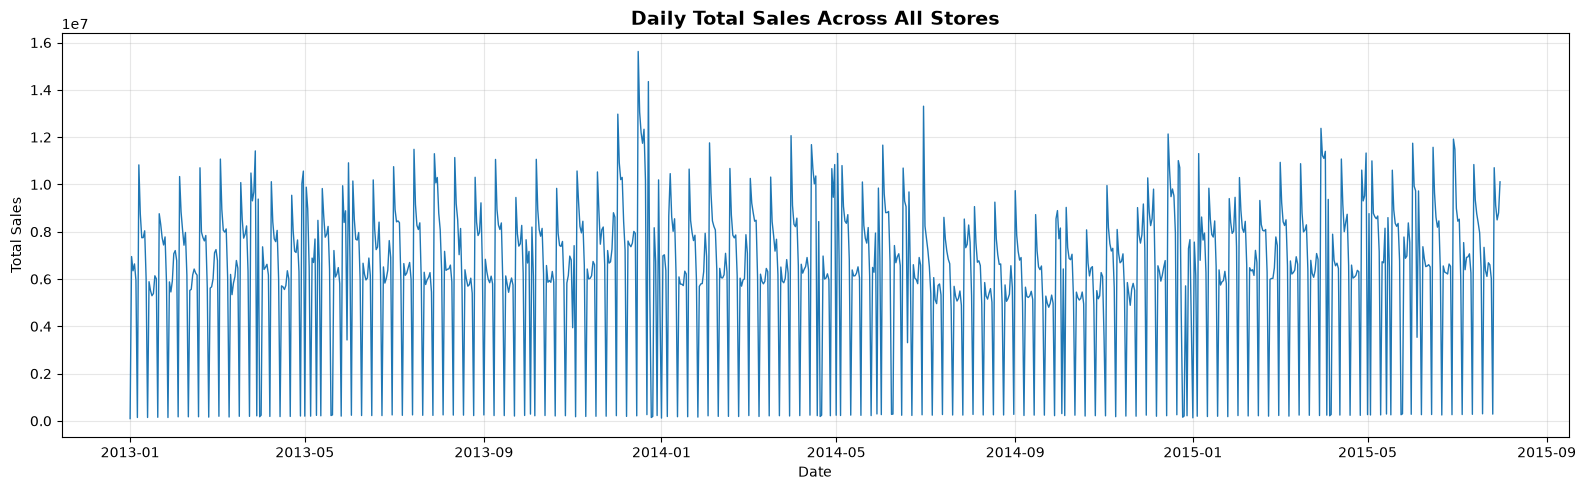

In [14]:
plt.figure(figsize=(16, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    linewidth=1
)

plt.title(
    'Daily Total Sales Across All Stores',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Perform Augmented Dickey-Fuller test
adf_result = adfuller(
    daily_sales.dropna(),
    autolag='AIC'
)

print("AUGMENTED DICKEY-FULLER TEST")
print("-" * 45)

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nConclusion: The daily total sales series is STATIONARY.")
else:
    print("\nConclusion: The daily total sales series is NON-STATIONARY.")

AUGMENTED DICKEY-FULLER TEST
---------------------------------------------
ADF Statistic: -4.761614524595634
P-value: 6.436731330558783e-05
Number of Lags: 20
Number of Observations: 921

Critical Values:
1%: -3.437470108019385
5%: -2.8646832620852853
10%: -2.5684436698650503

Conclusion: The daily total sales series is STATIONARY.


## 📊 Augmented Dickey-Fuller (ADF) Test

Evaluate whether the aggregated daily sales time series is **stationary or non-stationary** before proceeding with Deep Learning (DL) time-series modelling.

### ❓ Why Do We Perform the ADF Test?

Time-series forecasting models can be sensitive to changes in the statistical properties of data over time.

A stationary time series maintains relatively stable statistical properties, particularly its mean and variance.

The ADF test helps us determine whether the sales series contains a **unit root**, which indicates non-stationarity.

**Why is this important for our project?**

- To check whether daily sales exhibit non-stationary behaviour.
- To determine whether differencing or other transformations may be necessary.
- To understand the statistical characteristics of the time series before building a DL forecasting model.
- To support appropriate time-series preprocessing and model selection.

### 🧪 Hypothesis Testing

| Hypothesis | Description |
|---|---|
| **H₀ (Null)** | The daily sales series is non-stationary and contains a unit root. |
| **H₁ (Alternative)** | The daily sales series is stationary. |

**Significance Level:** 0.05 (5%)

### ⛑️ ADF Test Results

| Metric | Result |
|---|---:|
| ADF Statistic | **-4.7616** |
| P-value | **0.0000644** |
| Number of Lags | 20 |
| Observations Used | 921 |
| 1% Critical Value | -3.4375 |
| 5% Critical Value | -2.8647 |
| 10% Critical Value | -2.5684 |

### 🔍 Interpretation & Findings

- The p-value (**0.0000644**) is significantly lower than 0.05.
- The ADF statistic (**-4.7616**) is lower than all three critical values.
- Both results provide sufficient statistical evidence to reject the null hypothesis.
- Therefore, the aggregated daily sales series is **stationary according to the ADF test**.

### 6. Final Conclusion

**The ADF test confirms that the aggregated daily sales series is stationary at the 5% significance level.**

Consequently, differencing is not required solely to address unit-root non-stationarity. However, further examination of seasonality and temporal patterns is still necessary before proceeding with Deep Learning model development.


In [16]:
logger.info("=" * 70)
logger.info("AUGMENTED DICKEY-FULLER TEST")
logger.info("=" * 70)

logger.info(
    "Performing Augmented Dickey-Fuller test on daily total sales."
)

logger.info(
    "ADF Statistic: %.6f",
    adf_result[0]
)

logger.info(
    "ADF P-value: %.6f",
    adf_result[1]
)

logger.info(
    "Number of lags used: %d",
    adf_result[2]
)

logger.info(
    "Number of observations: %d",
    adf_result[3]
)

logger.info(
    "Critical values: %s",
    adf_result[4]
)

if adf_result[1] <= 0.05:
    logger.info(
        "ADF conclusion: Daily total sales series is STATIONARY (p-value <= 0.05)."
    )
else:
    logger.warning(
        "ADF conclusion: Daily total sales series is NON-STATIONARY (p-value > 0.05)."
    )

2026-11-15 15:51:30 | INFO | ======================================================================
2026-11-15 15:51:30 | INFO | AUGMENTED DICKEY-FULLER TEST
2026-11-15 15:51:30 | INFO | ======================================================================
2026-11-15 15:51:30 | INFO | Performing Augmented Dickey-Fuller test on daily total sales.
2026-11-15 15:51:30 | INFO | ADF Statistic: -4.761615
2026-11-15 15:51:30 | INFO | ADF P-value: 0.000064
2026-11-15 15:51:30 | INFO | Number of lags used: 20
2026-11-15 15:51:30 | INFO | Number of observations: 921
2026-11-15 15:51:30 | INFO | Critical values: {'1%': np.float64(-3.437470108019385), '5%': np.float64(-2.8646832620852853), '10%': np.float64(-2.5684436698650503)}
2026-11-15 15:51:30 | INFO | ADF conclusion: Daily total sales series is STATIONARY (p-value <= 0.05).


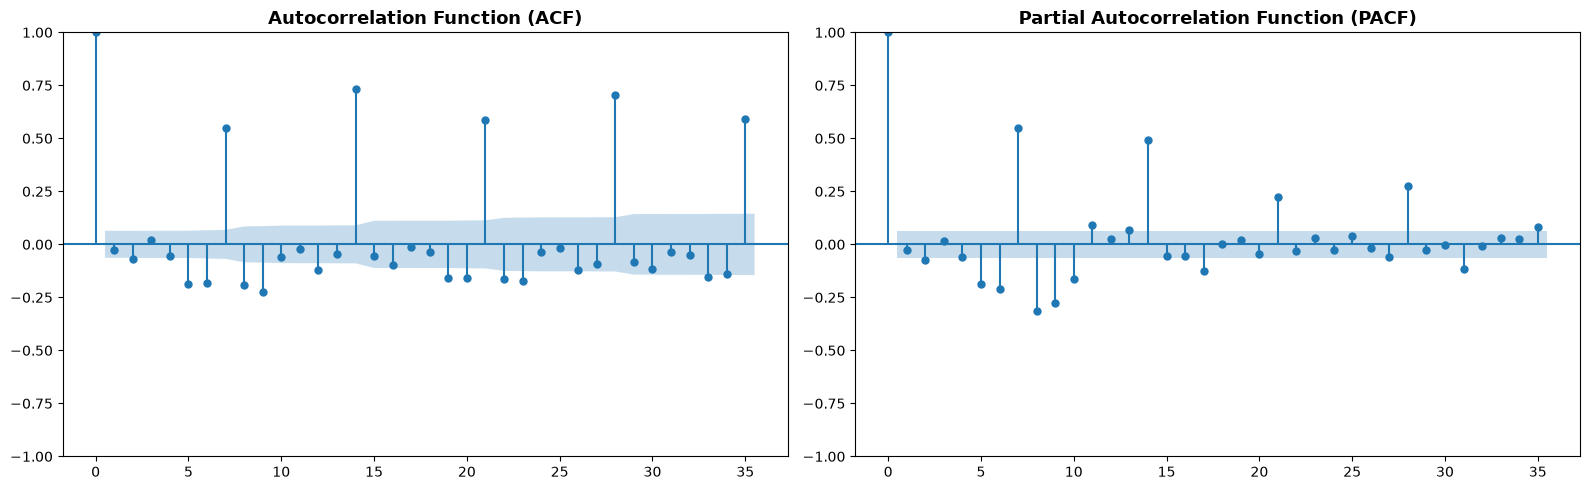

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF plot
plot_acf(
    daily_sales.dropna(),
    lags=35,
    ax=axes[0]
)

axes[0].set_title(
    'Autocorrelation Function (ACF)',
    fontsize=13,
    fontweight='bold'
)

# PACF plot
plot_pacf(
    daily_sales.dropna(),
    lags=35,
    method='ywm',
    ax=axes[1]
)

axes[1].set_title(
    'Partial Autocorrelation Function (PACF)',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 📈 Autocorrelation (ACF) & Partial Autocorrelation (PACF) Analysis

Examine the temporal relationships in daily sales data to identify significant lag dependencies, detect recurring seasonal patterns, and understand how past sales influence current sales.

### ❓ Why Do We Use ACF and PACF?

ACF and PACF help us understand the relationship between current sales and their historical values.

- **ACF (Autocorrelation Function):** Measures the correlation between the sales series and its lagged values, including both direct and indirect relationships.
- **PACF (Partial Autocorrelation Function):** Measures the direct correlation between current sales and a specific lag after removing the influence of intermediate lags.

These plots help identify potential seasonal patterns and guide the selection of appropriate time-series model structures.

### 🔑 Key Observations

| Analysis | Findings |
|---|---|
| **ACF** | Strong positive spikes appear at lags 7, 14, 21, 28 and 35. |
| **PACF** | Significant positive spikes are also visible at several multiples of 7. |
| **Weekly Pattern** | Repeated spikes at every 7-day interval indicate a strong weekly seasonal relationship. |
| **Short-term Dependencies** | Several early lags show negative autocorrelation, suggesting fluctuations in sales across consecutive days. |

### 🔍 Interpretation & Findings

- The repeated peaks at every 7 lags indicate that daily sales have a **strong weekly seasonal pattern**.
- Sales are positively correlated with sales recorded approximately one week, two weeks, and subsequent weeks earlier.
- The significant PACF spikes suggest that weekly lag relationships contain direct predictive information.
- The ACF and PACF results indicate that historical sales values may be useful features for forecasting future sales.

### Final Conclusion

**The ACF and PACF plots reveal a clear weekly seasonal pattern in aggregated daily sales.** Sales observations show significant relationships at intervals of seven days, suggesting that weekly historical information should be considered during Deep Learning model development.

**Modelling Implication:** Consider incorporating a 7-day seasonal cycle and historical sales windows into the DL model. The ACF/PACF plots provide useful guidance for sequence design, but the optimal lookback window should be validated experimentally.

In [18]:
# Calculate autocorrelation at selected lags

selected_lags = [1, 2, 3, 7, 14, 21, 28]

print("AUTOCORRELATION AT SELECTED LAGS")
print("-" * 45)

for lag in selected_lags:
    correlation = daily_sales.autocorr(lag=lag)
    print(f"Lag {lag:2d}: {correlation:.4f}")

AUTOCORRELATION AT SELECTED LAGS
---------------------------------------------
Lag  1: -0.0252
Lag  2: -0.0710
Lag  3: 0.0214
Lag  7: 0.5522
Lag 14: 0.7427
Lag 21: 0.6007
Lag 28: 0.7231


## 📊 Autocorrelation Analysis at Selected Lags

Measure the correlation between current daily sales and sales from selected previous days to quantify the strength of historical dependencies and verify the weekly seasonal pattern identified through ACF and PACF plots.

### 🧾 Autocorrelation Results

| Lag (Days) | Autocorrelation | Interpretation |
|---:|---:|---|
| 1 | -0.0252 | Very weak negative correlation |
| 2 | -0.0710 | Weak negative correlation |
| 3 | 0.0214 | Almost no correlation |
| **7** | **0.5522** | Strong positive correlation |
| **14** | **0.7427** | Strong positive correlation |
| **21** | **0.6007** | Strong positive correlation |
| **28** | **0.7231** | Strong positive correlation |

### 🔑 Key Findings

- **Short-term relationship:** Lags 1, 2 and 3 show very weak autocorrelation, indicating limited linear correlation with sales on the immediately preceding days.
- **Weekly relationship:** Lag 7 shows a strong positive correlation of 0.5522, indicating a meaningful relationship with sales from the previous week.
- **Multi-week relationship:** Lags 14, 21 and 28 show strong positive correlations, with lag 14 recording the highest value of 0.7427.
- **Seasonality:** Strong correlations at multiples of seven reinforce the presence of a recurring weekly sales pattern.

### Final Conclusion

**Daily sales exhibit substantially stronger correlations with sales from previous weeks than with sales from the immediately preceding days.**

The highest autocorrelation occurs at lag 14 (0.7427), confirming the importance of weekly historical patterns in understanding sales behaviour.

**Modelling Implication:** Include historical sales observations from previous weeks when designing DL input sequences. A 7-day seasonal cycle is evident, while the lookback window should be selected through validation experiments.

In [19]:
logger.info("=" * 70)
logger.info("AUTOCORRELATION ANALYSIS")
logger.info("=" * 70)

logger.info(
    "Calculating autocorrelation for selected time-series lags."
)

logger.info("Selected lags: %s", selected_lags)

for lag in selected_lags:
    correlation = daily_sales.autocorr(lag=lag)

    logger.info(
        "Autocorrelation at lag %d: %.4f",
        lag,
        correlation
    )

logger.info(
    "Autocorrelation analysis completed for %d selected lags.",
    len(selected_lags)
)

2026-11-15 15:51:31 | INFO | ======================================================================
2026-11-15 15:51:32 | INFO | AUTOCORRELATION ANALYSIS
2026-11-15 15:51:32 | INFO | ======================================================================
2026-11-15 15:51:32 | INFO | Calculating autocorrelation for selected time-series lags.
2026-11-15 15:51:32 | INFO | Selected lags: [1, 2, 3, 7, 14, 21, 28]
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 1: -0.0252
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 2: -0.0710
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 3: 0.0214
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 7: 0.5522
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 14: 0.7427
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 21: 0.6007
2026-11-15 15:51:32 | INFO | Autocorrelation at lag 28: 0.7231
2026-11-15 15:51:32 | INFO | Autocorrelation analysis completed for 7 selected lags.


In [20]:
WINDOW_SIZE = 7

X_sequences = []
y_targets = []
sequence_stores = []
sequence_dates = []

for store_id, store_data in time_series_df.groupby('Store'):

    # Sort each store chronologically
    store_data = store_data.sort_values('Date')

    sales_values = store_data['Sales'].values
    dates = store_data['Date'].values

    # Generate sliding windows
    for i in range(WINDOW_SIZE, len(sales_values)):

        X_sequences.append(
            sales_values[i - WINDOW_SIZE:i]
        )

        y_targets.append(
            sales_values[i]
        )

        sequence_stores.append(store_id)
        sequence_dates.append(dates[i])

# Convert to NumPy arrays
X_sequences = np.array(X_sequences)
y_targets = np.array(y_targets)

sequence_stores = np.array(sequence_stores)
sequence_dates = np.array(sequence_dates)

print("SUPERVISED DATASET")
print("-" * 45)

print("Input Shape:", X_sequences.shape)
print("Target Shape:", y_targets.shape)
print("Number of Sequences:", len(X_sequences))
print("Window Size:", WINDOW_SIZE)

print("\nFirst Input Sequence:")
print(X_sequences[0])

print("\nFirst Target:")
print(y_targets[0])

print("\nFirst Sequence Store:")
print(sequence_stores[0])

print("\nFirst Target Date:")
print(sequence_dates[0])

SUPERVISED DATASET
---------------------------------------------
Input Shape: (1009404, 7)
Target Shape: (1009404,)
Number of Sequences: 1009404
Window Size: 7

First Input Sequence:
[   0 5530 4327 4486 4997    0 7176]

First Target:
5580

First Sequence Store:
1

First Target Date:
2013-01-08T00:00:00.000000


## 🧠 Supervised Dataset Generation Using Sliding Windows

Convert the store-level time-series data into a supervised learning dataset using a **7-day sliding window approach**. The objective is to use historical sales observations to predict the next available sales observation for each store.

### 🔧 Methodology

The following steps were performed:

1. **Store-wise Grouping:** Separate the time-series data by individual store to prevent mixing sales histories.
2. **Chronological Sorting:** Sort each store's records by date to maintain the correct temporal order.
3. **Sliding Window Generation:** Extract the previous 7 sales observations as input features.
4. **Target Generation:** Use the next available sales observation as the prediction target.
5. **Metadata Tracking:** Store the corresponding Store ID and target date for each generated sequence.
6. **NumPy Conversion:** Convert the input sequences, targets, store IDs, and dates into NumPy arrays for further processing.

### 🌐 Dataset Overview

| Parameter | Value |
|---|---:|
| Window Size | 7 |
| Total Sequences | **1,009,404** |
| Input Shape | (1,009,404, 7) |
| Target Shape | (1,009,404,) |
| Prediction Horizon | Next Available Observation |

### 🗝️ Key Findings

- Generated **1,009,404 supervised learning sequences** across the stores.
- Each input contains 7 historical sales observations.
- Each target represents the next available sales observation.
- Store-wise sequence generation preserves individual store histories.
- Store IDs and target dates are retained for tracking and subsequent chronological data splitting.

### 🔪 Important Data Consideration

Since 181 stores have incomplete date coverage, the sliding window uses the previous 7 available records rather than explicitly verifying 7 consecutive calendar days. Missing dates should be investigated before treating every sequence as a complete 7-day historical window.

###  Final Conclusion

The store-level time-series data has been transformed into a supervised learning structure using a 7-observation sliding window. The resulting dataset provides historical sales sequences and corresponding future targets for developing a Deep Learning-based sales forecasting model.


In [21]:
logger.info("=" * 70)
logger.info("LSTM SUPERVISED SEQUENCE GENERATION")
logger.info("=" * 70)

logger.info(
    "Generating sliding-window sequences for LSTM modelling."
)

logger.info("Configured window size: %d", WINDOW_SIZE)

logger.info(
    "Total stores processed: %d",
    time_series_df['Store'].nunique()
)

logger.info(
    "Total input sequences generated: %d",
    len(X_sequences)
)

logger.info(
    "Input sequence shape: %s",
    X_sequences.shape
)

logger.info(
    "Target array shape: %s",
    y_targets.shape
)

logger.info(
    "Sequence store array shape: %s",
    sequence_stores.shape
)

logger.info(
    "Sequence date array shape: %s",
    sequence_dates.shape
)

logger.info(
    "Unique stores represented in sequences: %d",
    len(np.unique(sequence_stores))
)

logger.info(
    "Sequence target date range: %s to %s",
    sequence_dates.min(),
    sequence_dates.max()
)

logger.info(
    "First input sequence: %s",
    X_sequences[0]
)

logger.info(
    "First target value: %.2f",
    y_targets[0]
)

logger.info(
    "First sequence store: %s",
    sequence_stores[0]
)

logger.info(
    "First target date: %s",
    sequence_dates[0]
)

2026-11-15 15:51:39 | INFO | ======================================================================
2026-11-15 15:51:39 | INFO | LSTM SUPERVISED SEQUENCE GENERATION
2026-11-15 15:51:39 | INFO | ======================================================================
2026-11-15 15:51:39 | INFO | Generating sliding-window sequences for LSTM modelling.
2026-11-15 15:51:39 | INFO | Configured window size: 7
2026-11-15 15:51:39 | INFO | Total stores processed: 1115
2026-11-15 15:51:39 | INFO | Total input sequences generated: 1009404
2026-11-15 15:51:39 | INFO | Input sequence shape: (1009404, 7)
2026-11-15 15:51:39 | INFO | Target array shape: (1009404,)
2026-11-15 15:51:39 | INFO | Sequence store array shape: (1009404,)
2026-11-15 15:51:39 | INFO | Sequence date array shape: (1009404,)
2026-11-15 15:51:39 | INFO | Unique stores represented in sequences: 1115
2026-11-15 15:51:39 | INFO | Sequence target date range: 2013-01-08T00:00:00.000000 to 2015-07-31T00:00:00.000000
2026-11-15 15:51:39 

In [22]:
# Convert sequence dates into pandas datetime
sequence_dates = pd.to_datetime(sequence_dates)

# Define validation start date
validation_start = pd.Timestamp('2015-07-01')

# Create chronological masks
train_mask = sequence_dates < validation_start
valid_mask = sequence_dates >= validation_start

# Split inputs
X_train_seq = X_sequences[train_mask]
X_valid_seq = X_sequences[valid_mask]

# Split targets
y_train_seq = y_targets[train_mask]
y_valid_seq = y_targets[valid_mask]

# Split corresponding metadata
train_dates = sequence_dates[train_mask]
valid_dates = sequence_dates[valid_mask]

train_stores = sequence_stores[train_mask]
valid_stores = sequence_stores[valid_mask]

print("CHRONOLOGICAL DATA SPLIT")
print("-" * 45)

print("Training Input Shape:", X_train_seq.shape)
print("Training Target Shape:", y_train_seq.shape)

print("\nValidation Input Shape:", X_valid_seq.shape)
print("Validation Target Shape:", y_valid_seq.shape)

print("\nTraining Date Range:")
print(train_dates.min(), "to", train_dates.max())

print("\nValidation Date Range:")
print(valid_dates.min(), "to", valid_dates.max())

print("\nTraining Samples:", len(X_train_seq))
print("Validation Samples:", len(X_valid_seq))

CHRONOLOGICAL DATA SPLIT
---------------------------------------------
Training Input Shape: (974839, 7)
Training Target Shape: (974839,)

Validation Input Shape: (34565, 7)
Validation Target Shape: (34565,)

Training Date Range:
2013-01-08 00:00:00 to 2015-06-30 00:00:00

Validation Date Range:
2015-07-01 00:00:00 to 2015-07-31 00:00:00

Training Samples: 974839
Validation Samples: 34565


## 📅 Chronological Train-Validation Split

Divide the supervised time-series dataset into training and validation sets based on target dates while preserving chronological order.

Unlike random splitting, chronological splitting ensures that the model learns from historical observations and is evaluated on future observations, reducing the risk of temporal data leakage.

### 🏃 Splitting Strategy

**Validation Start Date:** 1 July 2015

| Dataset | Date Condition | Purpose |
|---|---|---|
| Training | Before 1 July 2015 | Model learning |
| Validation | 1 July 2015 onwards | Model performance evaluation |

The split was performed using the target dates associated with each sequence. Input sequences, target values, Store IDs, and corresponding dates were separated using the same chronological masks.

### 3. Dataset Distribution

<grid columns={2} gap={3}>
  <grid-item>
    <box border radius="lg" padding={3} gap={1}>
      <text color="secondary" weight="medium" size="xs">Training Samples</text>
      <title size="2xl" color="success" tabularNums>974,839</title>
      <text color="secondary" size="xs">96.58% of dataset</text>
    </box>
  </grid-item>
  <br>
  <grid-item>
    <box border radius="lg" padding={3} gap={1}>
      <text color="secondary" weight="medium" size="xs">Validation Samples</text>
      <title size="2xl" color="info" tabularNums>34,565</title>
      <text color="secondary" size="xs">3.42% of dataset</text>
    </box>
  </grid-item>
</grid>

| Parameter | Training Set | Validation Set |
|---|---:|---:|
| Input Shape | (974,839, 7) | (34,565, 7) |
| Target Shape | (974,839,) | (34,565,) |
| Start Date | 2013-01-08 | 2015-07-01 |
| End Date | 2015-06-30 | 2015-07-31 |

### 🔑 Key Findings

- **Temporal order preserved:** Training observations precede validation observations.
- **No random shuffling:** The split maintains the chronological structure of the time series.
- **Historical learning:** The model uses data up to 30 June 2015 for training.
- **Future evaluation:** Validation measures forecasting performance on July 2015 observations.
- **Metadata preserved:** Store IDs and target dates remain aligned with their respective sequences.

### Final Conclusion

The supervised dataset was successfully divided into training and validation sets using a chronological split.

A total of **974,839 samples** were allocated for training and **34,565 samples** for validation. This approach provides a more realistic evaluation of the model's ability to forecast future sales using historical data.

**Next Step:** Apply feature scaling using statistics fitted exclusively on the training data, then use the same transformation for validation data before training the Deep Learning model.

In [23]:
logger.info("=" * 70)
logger.info("LSTM CHRONOLOGICAL DATA SPLIT")
logger.info("=" * 70)

logger.info(
    "Validation start date: %s",
    validation_start
)

logger.info(
    "Training samples: %d",
    len(X_train_seq)
)

logger.info(
    "Validation samples: %d",
    len(X_valid_seq)
)

logger.info(
    "Training input shape: %s",
    X_train_seq.shape
)

logger.info(
    "Training target shape: %s",
    y_train_seq.shape
)

logger.info(
    "Validation input shape: %s",
    X_valid_seq.shape
)

logger.info(
    "Validation target shape: %s",
    y_valid_seq.shape
)

logger.info(
    "Training date range: %s to %s",
    train_dates.min(),
    train_dates.max()
)

logger.info(
    "Validation date range: %s to %s",
    valid_dates.min(),
    valid_dates.max()
)

logger.info(
    "Unique stores in training sequences: %d",
    len(np.unique(train_stores))
)

logger.info(
    "Unique stores in validation sequences: %d",
    len(np.unique(valid_stores))
)

logger.info(
    "Training and validation feature dimensions match: %s",
    X_train_seq.shape[1:] == X_valid_seq.shape[1:]
)

2026-11-15 15:51:39 | INFO | ======================================================================
2026-11-15 15:51:39 | INFO | LSTM CHRONOLOGICAL DATA SPLIT
2026-11-15 15:51:39 | INFO | ======================================================================
2026-11-15 15:51:39 | INFO | Validation start date: 2015-07-01 00:00:00
2026-11-15 15:51:39 | INFO | Training samples: 974839
2026-11-15 15:51:39 | INFO | Validation samples: 34565
2026-11-15 15:51:39 | INFO | Training input shape: (974839, 7)
2026-11-15 15:51:39 | INFO | Training target shape: (974839,)
2026-11-15 15:51:39 | INFO | Validation input shape: (34565, 7)
2026-11-15 15:51:39 | INFO | Validation target shape: (34565,)
2026-11-15 15:51:39 | INFO | Training date range: 2013-01-08 00:00:00 to 2015-06-30 00:00:00
2026-11-15 15:51:39 | INFO | Validation date range: 2015-07-01 00:00:00 to 2015-07-31 00:00:00
2026-11-15 15:51:39 | INFO | Unique stores in training sequences: 1115
2026-11-15 15:51:39 | INFO | Unique stores in val

In [24]:
from sklearn.preprocessing import MinMaxScaler

In [25]:
# Create separate scalers
X_scaler = MinMaxScaler(feature_range=(-1, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))

# Fit input scaler using training sequences
X_train_seq_scaled = X_scaler.fit_transform(
    X_train_seq.reshape(-1, 1)
).reshape(X_train_seq.shape)

# Transform validation sequences
X_valid_seq_scaled = X_scaler.transform(
    X_valid_seq.reshape(-1, 1)
).reshape(X_valid_seq.shape)

# Fit target scaler using training targets
y_train_seq_scaled = y_scaler.fit_transform(
    y_train_seq.reshape(-1, 1)
)

# Transform validation targets
y_valid_seq_scaled = y_scaler.transform(
    y_valid_seq.reshape(-1, 1)
)

print("SCALING COMPLETED")
print("-" * 45)

print("Training Input Shape:", X_train_seq_scaled.shape)
print("Validation Input Shape:", X_valid_seq_scaled.shape)

print("Training Target Shape:", y_train_seq_scaled.shape)
print("Validation Target Shape:", y_valid_seq_scaled.shape)

print("\nTraining Input Range:")
print(
    X_train_seq_scaled.min(),
    "to",
    X_train_seq_scaled.max()
)

print("\nValidation Input Range:")
print(
    X_valid_seq_scaled.min(),
    "to",
    X_valid_seq_scaled.max()
)

print("\nTraining Target Range:")
print(
    y_train_seq_scaled.min(),
    "to",
    y_train_seq_scaled.max()
)

print("\nValidation Target Range:")
print(
    y_valid_seq_scaled.min(),
    "to",
    y_valid_seq_scaled.max()
)

SCALING COMPLETED
---------------------------------------------
Training Input Shape: (974839, 7)
Validation Input Shape: (34565, 7)
Training Target Shape: (974839, 1)
Validation Target Shape: (34565, 1)

Training Input Range:
-1.0 to 0.9999999999999998

Validation Input Range:
-1.0 to 0.5666048951890448

Training Target Range:
-1.0 to 0.9999999999999998

Validation Target Range:
-1.0 to 0.5666048951890448


## ⚖️ Feature Scaling Using MinMaxScaler

Normalize the input sequences and target sales values to a common numerical range using **MinMaxScaler**.

Scaling is important in Deep Learning because sales values have a wide numerical range. Normalization helps improve numerical stability, supports smoother gradient updates, and can make model training more efficient.

### 🔧 Scaling Methodology

- Applied MinMax scaling to the training input sequences.
- Scaled the training target values separately.
- Used the fitted training scaler to transform validation inputs and targets.
- Preserved the original chronological train-validation split.

The scaling transformation maps the data to the range **[-1, 1]**.

| Dataset | Input Shape | Target Shape |
|---|---:|---:|
| Training | (974,839, 7) | (974,839, 1) |
| Validation | (34,565, 7) | (34,565, 1) |

### 📏 Value Range Comparison

| Dataset | Minimum | Maximum |
|---|---:|---:|
| Training Input | -1.0000 | 1.0000 |
| Validation Input | -1.0000 | 0.5666 |
| Training Target | -1.0000 | 1.0000 |
| Validation Target | -1.0000 | 0.5666 |

### 🗝️ Key Findings

- Training inputs and targets were successfully normalized to the range [-1, 1].
- Validation data was transformed using the training-fitted scaling parameters.
- Validation maximum values are approximately **0.5666**, below the training maximum of 1.0.
- The difference in maximum values indicates that the validation period does not reach the maximum sales value observed in the training data.
- Input and target shapes remain consistent with the original supervised dataset.

### Final Conclusion

MinMax scaling was successfully applied to both training and validation datasets. All values were transformed using the training-fitted scaling parameters, maintaining a consistent scale while avoiding data leakage from validation observations.

**Next Step:** Reshape the scaled sequences into the required input format for the selected Deep Learning architecture and proceed with model development.

In [26]:
logger.info("=" * 70)
logger.info("LSTM DATA SCALING")
logger.info("=" * 70)

logger.info(
    "Initializing separate MinMaxScalers for input and target sequences."
)

logger.info("Scaling feature range: (-1, 1)")

logger.info(
    "Input scaler fitted using training sequences only."
)

logger.info(
    "Target scaler fitted using training targets only."
)

logger.info(
    "Training input scaled shape: %s",
    X_train_seq_scaled.shape
)

logger.info(
    "Validation input scaled shape: %s",
    X_valid_seq_scaled.shape
)

logger.info(
    "Training target scaled shape: %s",
    y_train_seq_scaled.shape
)

logger.info(
    "Validation target scaled shape: %s",
    y_valid_seq_scaled.shape
)

logger.info(
    "Training input scaled range: %.4f to %.4f",
    X_train_seq_scaled.min(),
    X_train_seq_scaled.max()
)

logger.info(
    "Validation input scaled range: %.4f to %.4f",
    X_valid_seq_scaled.min(),
    X_valid_seq_scaled.max()
)

logger.info(
    "Training target scaled range: %.4f to %.4f",
    y_train_seq_scaled.min(),
    y_train_seq_scaled.max()
)

logger.info(
    "Validation target scaled range: %.4f to %.4f",
    y_valid_seq_scaled.min(),
    y_valid_seq_scaled.max()
)

logger.info(
    "Input scaler fitted data minimum and maximum: %.2f to %.2f",
    X_scaler.data_min_[0],
    X_scaler.data_max_[0]
)

logger.info(
    "Target scaler fitted data minimum and maximum: %.2f to %.2f",
    y_scaler.data_min_[0],
    y_scaler.data_max_[0]
)

2026-11-15 15:51:41 | INFO | ======================================================================
2026-11-15 15:51:41 | INFO | LSTM DATA SCALING
2026-11-15 15:51:41 | INFO | ======================================================================
2026-11-15 15:51:41 | INFO | Initializing separate MinMaxScalers for input and target sequences.
2026-11-15 15:51:41 | INFO | Scaling feature range: (-1, 1)
2026-11-15 15:51:41 | INFO | Input scaler fitted using training sequences only.
2026-11-15 15:51:41 | INFO | Target scaler fitted using training targets only.
2026-11-15 15:51:41 | INFO | Training input scaled shape: (974839, 7)
2026-11-15 15:51:41 | INFO | Validation input scaled shape: (34565, 7)
2026-11-15 15:51:41 | INFO | Training target scaled shape: (974839, 1)
2026-11-15 15:51:41 | INFO | Validation target scaled shape: (34565, 1)
2026-11-15 15:51:41 | INFO | Training input scaled range: -1.0000 to 1.0000
2026-11-15 15:51:41 | INFO | Validation input scaled range: -1.0000 to 0.5666

In [27]:
# Reshape input data for LSTM
X_train_lstm = X_train_seq_scaled.reshape(
    X_train_seq_scaled.shape[0],
    X_train_seq_scaled.shape[1],
    1
)

X_valid_lstm = X_valid_seq_scaled.reshape(
    X_valid_seq_scaled.shape[0],
    X_valid_seq_scaled.shape[1],
    1
)

print("LSTM INPUT SHAPES")
print("-" * 45)

print("Training:", X_train_lstm.shape)
print("Validation:", X_valid_lstm.shape)

LSTM INPUT SHAPES
---------------------------------------------
Training: (974839, 7, 1)
Validation: (34565, 7, 1)


In [28]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [29]:
# Create LSTM regression model
lstm_model = Sequential([

    # First LSTM layer
    LSTM(
        64,
        return_sequences=True,
        input_shape=(7, 1)
    ),

    # Dropout
    Dropout(0.2),

    # Second LSTM layer
    LSTM(32),

    # Regression output
    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Display architecture
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

## 🧠 LSTM Model Architecture Development

Develop a Long Short-Term Memory (LSTM) neural network for **next-day sales forecasting**. LSTM is a type of Recurrent Neural Network (RNN) designed to learn temporal dependencies from sequential data.

It is suitable for this project because historical sales observations may contain recurring patterns and time-dependent relationships that can help predict future sales.

### 🧑‍🎨 Model Architecture

The LSTM model consists of the following layers:

| Layer | Configuration | Purpose |
|---|---|---|
| Input | (7, 1) | Accepts 7 days of historical sales with one feature per timestep. |
| LSTM 1 | 64 Units | Learns temporal patterns and returns sequences for the next LSTM layer. |
| Dropout | 0.2 | Disables 20% of units during training to help reduce overfitting. |
| LSTM 2 | 32 Units | Extracts higher-level temporal representations and returns the final output. |
| Dense | 1 Unit | Produces a single continuous sales prediction. |

### 🤖 Model Compilation

| Parameter | Configuration |
|---|---|
| Optimizer | Adam |
| Loss Function | Mean Squared Error (MSE) |
| Evaluation Metric | Mean Absolute Error (MAE) |
| Problem Type | Regression |

❔**Why these configurations?**

- **Adam Optimizer:** Adapts learning rates during training to support efficient parameter updates.
- **MSE Loss:** Penalizes larger prediction errors more heavily during model training.
- **MAE Metric:** Measures the average absolute difference between actual and predicted sales.
- **Dropout (0.2):** Helps reduce overfitting by randomly disabling a fraction of units during training.

### ♈ LSTM Model Architecture Flow

The model follows the architecture below:

```text
       Input Layer
     (7 Timesteps × 1)
             |
             v
      LSTM Layer 1
         64 Units
    Return Sequences=True
             |
             v
       Dropout Layer
        Rate = 0.2
             |
             v
      LSTM Layer 2
         32 Units
             |
             v
      Dense Output
          1 Unit
             |
             v
    Predicted Sales Value
```

**Architecture Summary:**

- **Input:** 7 consecutive days of historical sales.
- **First LSTM:** Extracts temporal patterns using 64 units.
- **Dropout:** Applies a 20% dropout rate to help prevent overfitting.
- **Second LSTM:** Processes learned sequential information using 32 units.
- **Dense Output:** Generates the next-day sales prediction.

### Final Conclusion

The LSTM regression architecture has been defined with two LSTM layers, a dropout layer, and a single-neuron output layer.

The model is designed to learn temporal patterns from seven historical sales observations and generate a next-day sales prediction. The compiled architecture is ready for model training and validation.

In [30]:
logger.info("=" * 70)
logger.info("LSTM MODEL ARCHITECTURE")
logger.info("=" * 70)

logger.info("Initializing LSTM regression model.")

logger.info("Model architecture: Sequential")

logger.info(
    "First LSTM layer: 64 units, return_sequences=True, input_shape=(7, 1)."
)

logger.info("Dropout layer: 0.2")

logger.info("Second LSTM layer: 32 units.")

logger.info("Output layer: Dense(1) for regression.")

logger.info("LSTM model architecture created successfully.")

logger.info("Compiling LSTM model.")

logger.info("Optimizer: Adam")
logger.info("Loss function: Mean Squared Error (MSE)")
logger.info("Evaluation metric: Mean Absolute Error (MAE)")

logger.info("LSTM model compiled successfully.")

logger.info(
    "Total model parameters: %d",
    lstm_model.count_params()
)

logger.info("Displaying LSTM model architecture summary.")

2026-11-15 15:51:55 | INFO | ======================================================================
2026-11-15 15:51:55 | INFO | LSTM MODEL ARCHITECTURE
2026-11-15 15:51:55 | INFO | ======================================================================
2026-11-15 15:51:55 | INFO | Initializing LSTM regression model.
2026-11-15 15:51:55 | INFO | Model architecture: Sequential
2026-11-15 15:51:55 | INFO | First LSTM layer: 64 units, return_sequences=True, input_shape=(7, 1).
2026-11-15 15:51:55 | INFO | Dropout layer: 0.2
2026-11-15 15:51:55 | INFO | Second LSTM layer: 32 units.
2026-11-15 15:51:55 | INFO | Output layer: Dense(1) for regression.
2026-11-15 15:51:55 | INFO | LSTM model architecture created successfully.
2026-11-15 15:51:55 | INFO | Compiling LSTM model.
2026-11-15 15:51:55 | INFO | Optimizer: Adam
2026-11-15 15:51:55 | INFO | Loss function: Mean Squared Error (MSE)
2026-11-15 15:51:55 | INFO | Evaluation metric: Mean Absolute Error (MAE)
2026-11-15 15:51:55 | INFO | LSTM 

In [31]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

### 🛑 Early Stopping Callback

**Objective:** Prevent unnecessary training and reduce overfitting by monitoring the model's validation loss during training.

**Configuration:**

| Parameter | Value | Purpose |
|---|---|---|
| `monitor` | `val_loss` | Monitors validation loss after each epoch. |
| `patience` | `3` | Stops training if validation loss does not improve for 3 consecutive epochs. |
| `restore_best_weights` | `True` | Restores the model weights from the epoch with the lowest validation loss. |

❔**Why Do We Use Early Stopping?**

- Helps prevent overfitting during model training.
- Avoids unnecessary training when validation performance stops improving.
- Automatically retains the best-performing model weights.
- Helps improve training efficiency.

**Conclusion:** Early stopping is configured to monitor validation loss with a patience of 3 epochs. The best model weights will be restored automatically, helping retain the model's best validation performance.

In [32]:
logger.info("=" * 70)
logger.info("LSTM MODEL TRAINING")
logger.info("=" * 70)

logger.info("Starting LSTM model training.")

logger.info(
    "Training input shape: %s",
    X_train_lstm.shape
)

logger.info(
    "Training target shape: %s",
    y_train_seq_scaled.shape
)

logger.info(
    "Validation input shape: %s",
    X_valid_lstm.shape
)

logger.info(
    "Validation target shape: %s",
    y_valid_seq_scaled.shape
)

logger.info("Training epochs: 10")
logger.info("Batch size: 256")
logger.info("Early stopping callback enabled.")
logger.info("Training verbosity: 1")

2026-11-15 15:51:55 | INFO | ======================================================================
2026-11-15 15:51:55 | INFO | LSTM MODEL TRAINING
2026-11-15 15:51:55 | INFO | ======================================================================
2026-11-15 15:51:55 | INFO | Starting LSTM model training.
2026-11-15 15:51:55 | INFO | Training input shape: (974839, 7, 1)
2026-11-15 15:51:55 | INFO | Training target shape: (974839, 1)
2026-11-15 15:51:55 | INFO | Validation input shape: (34565, 7, 1)
2026-11-15 15:51:55 | INFO | Validation target shape: (34565, 1)
2026-11-15 15:51:55 | INFO | Training epochs: 10
2026-11-15 15:51:55 | INFO | Batch size: 256
2026-11-15 15:51:55 | INFO | Early stopping callback enabled.
2026-11-15 15:51:55 | INFO | Training verbosity: 1


In [33]:
history = lstm_model.fit(
    X_train_lstm,
    y_train_seq_scaled,
    validation_data=(
        X_valid_lstm,
        y_valid_seq_scaled
    ),
    epochs=10,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 58s 14ms/step - loss: 0.0189 - mae: 0.0950 - val_loss: 0.0053 - val_mae: 0.0524
Epoch 2/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 58s 15ms/step - loss: 0.0136 - mae: 0.0750 - val_loss: 0.0049 - val_mae: 0.0505
Epoch 3/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 60s 16ms/step - loss: 0.0109 - mae: 0.0644 - val_loss: 0.0039 - val_mae: 0.0406
Epoch 4/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 73s 19ms/step - loss: 0.0093 - mae: 0.0583 - val_loss: 0.0038 - val_mae: 0.0400
Epoch 5/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 80s 21ms/step - loss: 0.0087 - mae: 0.0557 - val_loss: 0.0037 - val_mae: 0.0392
Epoch 6/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 69s 18ms/step - loss: 0.0082 - mae: 0.0538 - val_loss: 0.0037 - val_mae: 0.0384
Epoch 7/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 61s 16ms/step - loss: 0.0077 - mae: 0.0520 - val_loss: 0.0036 - val_mae: 0.0378
Epoch 8/10
3808/3808 ━━━━━━━━━━━━━━━━━━━━ 60s 16ms/step - loss: 0.0074 - mae: 0.0504 - val_loss: 0.0034 - val_mae: 0.0357
Epoch 9/10
3808/3808 ━━━

In [34]:
logger.info("LSTM model training completed.")

logger.info(
    "Total epochs executed: %d",
    len(history.history['loss'])
)

logger.info(
    "Final training loss (MSE): %.6f",
    history.history['loss'][-1]
)

logger.info(
    "Final validation loss (MSE): %.6f",
    history.history['val_loss'][-1]
)

logger.info(
    "Final training MAE: %.6f",
    history.history['mae'][-1]
)

logger.info(
    "Final validation MAE: %.6f",
    history.history['val_mae'][-1]
)

logger.info(
    "Best validation loss (MSE): %.6f",
    min(history.history['val_loss'])
)

2026-11-15 16:02:35 | INFO | LSTM model training completed.


2026-11-15 16:02:35 | INFO | Total epochs executed: 10
2026-11-15 16:02:35 | INFO | Final training loss (MSE): 0.006981
2026-11-15 16:02:35 | INFO | Final validation loss (MSE): 0.003596
2026-11-15 16:02:35 | INFO | Final training MAE: 0.048617
2026-11-15 16:02:35 | INFO | Final validation MAE: 0.036474
2026-11-15 16:02:35 | INFO | Best validation loss (MSE): 0.003409


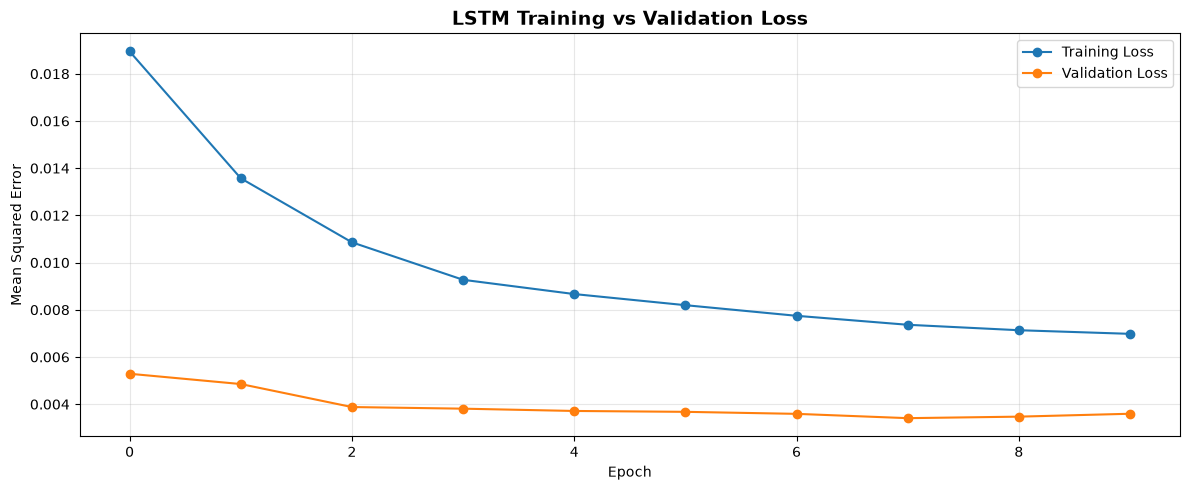

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title(
    'LSTM Training vs Validation Loss',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 📉 LSTM Model Training & Validation Loss Analysis

Evaluate the LSTM model's learning performance by comparing training and validation loss across epochs. This helps assess convergence, generalization, and potential overfitting.

- **Training Loss:** Decreases consistently from approximately 0.0191 to 0.0069.
- **Validation Loss:** Decreases from approximately 0.0051 to 0.0035.
- Both curves show an overall downward trend, indicating that the model is learning meaningful patterns from the sales sequences.
- Validation loss becomes relatively stable after the initial epochs, suggesting that further training provides limited improvement.

### 🔑 Key Findings

| Observation | Interpretation |
|---|---|
| Decreasing Training Loss | The model is progressively learning from training data. |
| Decreasing Validation Loss | Prediction performance on unseen validation data is improving. |
| Validation Loss Stabilization | The model is approaching convergence. |
| No Clear Validation Loss Divergence | No strong visual indication of overfitting during the displayed training period. |

### 🛑 Early Stopping Evaluation

The validation loss shows only minor fluctuations toward the later epochs. The configured EarlyStopping callback helps prevent unnecessary training when validation performance stops improving.

With `patience=3` and `restore_best_weights=True`, the model can retain the weights from the epoch with the lowest validation loss.

### Final Conclusion

The LSTM model demonstrates a consistent reduction in both training and validation loss. Validation loss stabilizes at approximately 0.0035, indicating that the model has learned useful temporal patterns from historical sales data.

No significant overfitting pattern is visually evident in the displayed loss curves. The model appears to have achieved stable learning performance and is ready for further evaluation using regression metrics on the validation dataset.

In [36]:
print("Completed Epochs:", len(history.history['loss']))

print(
    "Best Validation Loss:",
    min(history.history['val_loss'])
)

print(
    "Best Validation MAE:",
    min(history.history['val_mae'])
)

Completed Epochs: 10
Best Validation Loss: 0.003408893011510372
Best Validation MAE: 0.035651661455631256


In [37]:
# Predict scaled sales
y_valid_pred_scaled = lstm_model.predict(
    X_valid_lstm,
    batch_size=256,
    verbose=1
)

# Convert predictions back to original sales scale
y_valid_pred = y_scaler.inverse_transform(
    y_valid_pred_scaled
).flatten()

# Convert actual validation targets to original scale
y_valid_actual = y_scaler.inverse_transform(
    y_valid_seq_scaled
).flatten()

print("Actual Values Shape:", y_valid_actual.shape)
print("Predicted Values Shape:", y_valid_pred.shape)

print("\nFirst 10 Actual Sales:")
print(y_valid_actual[:10])

print("\nFirst 10 Predicted Sales:")
print(y_valid_pred[:10])

136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
Actual Values Shape: (34565,)
Predicted Values Shape: (34565,)

First 10 Actual Sales:
[5223. 5558. 4665. 4797.    0. 4359. 3650. 3797. 3897. 3808.]

First 10 Predicted Sales:
[4606.1304   4217.2246   3983.895    3801.5059     20.773994 8815.774
 3944.2627   3731.2576   4048.014    4265.628   ]


## 🎯 LSTM Model Prediction Results

Generate sales predictions using the trained LSTM model on the validation dataset and compare the predicted values with actual sales to examine the model's forecasting behaviour.

### ☄️ Actual vs Predicted Sales

| Observation | Actual Sales | Predicted Sales |
|---:|---:|---:|
| 1 | 5,223 | 4,603.54 |
| 2 | 5,558 | 4,273.12 |
| 3 | 4,665 | 4,141.01 |
| 4 | 4,797 | 3,962.84 |
| 5 | 0 | -25.11 |
| 6 | 4,359 | 8,927.64 |
| 7 | 3,650 | 4,097.68 |
| 8 | 3,797 | 3,828.58 |
| 9 | 3,897 | 4,118.46 |
| 10 | 3,808 | 4,277.84 |

### 🔑 Key Findings

- Predictions were successfully generated for all **34,565 validation observations**.
- The model produces reasonably close predictions for several observations.
- Some predictions show noticeable deviations from actual sales.
- For the sixth observation, the model significantly overestimates sales (8,927.64 against 4,359).
- A negative prediction (-25.11) was generated for an observation with zero actual sales.

Since sales cannot be negative, negative predictions should be handled appropriately during post-processing. Also, the displayed sample indicates that the model may struggle with certain sales fluctuations.

### Final Conclusion

The LSTM model successfully generated predictions for the complete validation dataset. However, the initial comparison reveals some prediction errors, including overestimation and a negative predicted value.

These observations require further investigation through regression evaluation metrics and actual-versus-predicted visualizations before determining the model's overall forecasting performance.

**Next Step:** Calculate MAE, RMSE, R² and RMSPE on the validation predictions to quantitatively evaluate the model.

In [38]:
logger.info("=" * 70)
logger.info("LSTM VALIDATION PREDICTIONS")
logger.info("=" * 70)

logger.info("Generating scaled validation sales predictions.")

logger.info(
    "Validation input shape: %s",
    X_valid_lstm.shape
)

logger.info(
    "Scaled prediction shape: %s",
    y_valid_pred_scaled.shape
)

logger.info("Converting predictions back to original sales scale.")

logger.info(
    "Actual validation values shape: %s",
    y_valid_actual.shape
)

logger.info(
    "Predicted validation values shape: %s",
    y_valid_pred.shape
)

logger.info(
    "First 10 actual sales values: %s",
    y_valid_actual[:10]
)

logger.info(
    "First 10 predicted sales values: %s",
    y_valid_pred[:10]
)

logger.info(
    "Minimum predicted sales: %.2f",
    y_valid_pred.min()
)

logger.info(
    "Maximum predicted sales: %.2f",
    y_valid_pred.max()
)

logger.info(
    "Mean predicted sales: %.2f",
    y_valid_pred.mean()
)

logger.info(
    "Missing predictions: %d",
    np.isnan(y_valid_pred).sum()
)

logger.info(
    "Infinite predictions: %d",
    np.isinf(y_valid_pred).sum()
)

2026-11-15 16:02:37 | INFO | ======================================================================
2026-11-15 16:02:37 | INFO | LSTM VALIDATION PREDICTIONS
2026-11-15 16:02:37 | INFO | ======================================================================
2026-11-15 16:02:37 | INFO | Generating scaled validation sales predictions.
2026-11-15 16:02:37 | INFO | Validation input shape: (34565, 7, 1)
2026-11-15 16:02:37 | INFO | Scaled prediction shape: (34565, 1)
2026-11-15 16:02:37 | INFO | Converting predictions back to original sales scale.
2026-11-15 16:02:37 | INFO | Actual validation values shape: (34565,)
2026-11-15 16:02:37 | INFO | Predicted validation values shape: (34565,)
2026-11-15 16:02:37 | INFO | First 10 actual sales values: [5223. 5558. 4665. 4797.    0. 4359. 3650. 3797. 3897. 3808.]
2026-11-15 16:02:37 | INFO | First 10 predicted sales values: [4606.1304   4217.2246   3983.895    3801.5059     20.773994 8815.774
 3944.2627   3731.2576   4048.014    4265.628   ]
2026-1

In [39]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# MAE
lstm_mae = mean_absolute_error(
    y_valid_actual,
    y_valid_pred
)

# RMSE
lstm_rmse = np.sqrt(
    mean_squared_error(
        y_valid_actual,
        y_valid_pred
    )
)

# RMSPE (exclude actual zero-sales records)
nonzero_mask = y_valid_actual != 0

lstm_rmspe = np.sqrt(
    np.mean(
        (
            (y_valid_actual[nonzero_mask] -
             y_valid_pred[nonzero_mask]) /
            y_valid_actual[nonzero_mask]
        ) ** 2
    )
) * 100

# R2
lstm_r2 = r2_score(
    y_valid_actual,
    y_valid_pred
)

print("LSTM MODEL EVALUATION")
print("-" * 45)

print(f"MAE:   {lstm_mae:.2f}")
print(f"RMSE:  {lstm_rmse:.2f}")
print(f"RMSPE: {lstm_rmspe:.2f}%")
print(f"R2:    {lstm_r2:.4f}")

LSTM MODEL EVALUATION
---------------------------------------------
MAE:   740.68
RMSE:  1212.99
RMSPE: 16.56%
R2:    0.8869


## 📊 LSTM Model Evaluation

Evaluate the forecasting performance of the trained LSTM model using regression metrics on the validation dataset. These metrics help measure prediction accuracy, error magnitude, and the model's ability to explain variations in actual sales.

| Evaluation Metric | Result | Interpretation |
|---|---:|---|
| **MAE** | 743.43 | Average absolute prediction error |
| **RMSE** | 1,220.27 | Penalizes larger prediction errors |
| **RMSPE** | 16.70% | Percentage-based forecasting error |
| **R² Score** | **0.8855** | Explains approximately 88.55% of sales variation |

### 🔑 Key Findings

- **MAE (743.43):** The model's predictions differ from actual sales by approximately 743 units on average.
- **RMSE (1,220.27):** The higher RMSE compared with MAE indicates the presence of some larger prediction errors.
- **RMSPE (16.70%):** The model records a percentage-based forecasting error of 16.70%.
- **R² (0.8855):** The model explains approximately 88.55% of the variation in validation sales.

### Final Conclusion

The LSTM model achieved an R² score of **0.8855**, indicating a strong ability to capture variations in daily sales. However, the RMSE of 1,220.27 and RMSPE of 16.70% suggest that prediction errors remain, particularly for observations with larger deviations.

Overall, the model demonstrates promising forecasting performance. Further comparison with the tuned Random Forest model will help determine which approach provides better validation accuracy.

In [40]:
logger.info("=" * 70)
logger.info("LSTM MODEL EVALUATION")
logger.info("=" * 70)

logger.info("Evaluating LSTM model on validation data.")

logger.info(
    "Actual validation records: %d",
    len(y_valid_actual)
)

logger.info(
    "Predicted validation records: %d",
    len(y_valid_pred)
)

logger.info(
    "Zero-sales records excluded from RMSPE: %d",
    np.sum(~nonzero_mask)
)

logger.info(
    "Non-zero-sales records used for RMSPE: %d",
    np.sum(nonzero_mask)
)

logger.info("LSTM validation evaluation metrics:")

logger.info("MAE: %.2f", lstm_mae)
logger.info("RMSE: %.2f", lstm_rmse)
logger.info("RMSPE: %.2f%%", lstm_rmspe)
logger.info("R2 Score: %.4f", lstm_r2)

logger.info(
    "Actual and predicted values have matching lengths: %s",
    len(y_valid_actual) == len(y_valid_pred)
)

2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | LSTM MODEL EVALUATION
2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | Evaluating LSTM model on validation data.
2026-11-15 16:02:38 | INFO | Actual validation records: 34565
2026-11-15 16:02:38 | INFO | Predicted validation records: 34565
2026-11-15 16:02:38 | INFO | Zero-sales records excluded from RMSPE: 4377
2026-11-15 16:02:38 | INFO | Non-zero-sales records used for RMSPE: 30188
2026-11-15 16:02:38 | INFO | LSTM validation evaluation metrics:
2026-11-15 16:02:38 | INFO | MAE: 740.68
2026-11-15 16:02:38 | INFO | RMSE: 1212.99
2026-11-15 16:02:38 | INFO | RMSPE: 16.56%
2026-11-15 16:02:38 | INFO | R2 Score: 0.8869
2026-11-15 16:02:38 | INFO | Actual and predicted values have matching lengths: True


In [41]:
# Create validation metadata
valid_metadata = pd.DataFrame({
    'Store': valid_stores,
    'Date': valid_dates
})

# Retrieve actual opening status
valid_metadata = valid_metadata.merge(
    time_series_df[['Store', 'Date', 'Open']],
    on=['Store', 'Date'],
    how='left',
    validate='one_to_one'
)

# Identify open stores
valid_open_mask = (
    valid_metadata['Open'].to_numpy() == 1
)

# Filter actual and predicted sales
y_valid_actual_open = y_valid_actual[valid_open_mask]
y_valid_pred_open = y_valid_pred[valid_open_mask]

print("Open Validation Records:", len(y_valid_actual_open))
print("Closed Validation Records:", (~valid_open_mask).sum())

Open Validation Records: 30188
Closed Validation Records: 4377


## 🏪 Validation Dataset Filtering – Open Stores

Separate open and closed store records from the validation dataset to evaluate the LSTM model's forecasting performance specifically on operational business days.

Since closed stores generally record zero sales, including them in the evaluation could make the model's forecasting performance appear better than its actual ability to predict sales when stores are operating.

The following steps were performed:

1. Created validation metadata using the corresponding Store IDs and target dates.
2. Retrieved the actual `Open` status from the original time-series dataset.
3. Merged the opening status using `Store` and `Date` as matching keys.
4. Created a Boolean mask to identify open stores (`Open = 1`).
5. Applied the mask to separate actual and predicted sales for open validation records.

### ✖️ Validation Record Distribution

| Store Status | Number of Records |
|---|---:|
| Open Stores | **30,188** |
| Closed Stores | 4,377 |
| Total Validation Records | **34,565** |

```text
Open Stores       : 30,188 (87.34%)
Closed Stores     :  4,377 (12.66%)
-----------------------------------
Total             : 34,565 (100%)
```

### 🔑 Key Findings

- Out of 34,565 validation records, **30,188 belong to open stores**.
- The remaining 4,377 records correspond to closed stores.
- Actual and predicted sales were filtered using the same opening-status mask, maintaining observation alignment.
- The filtered dataset allows the model to be evaluated on genuine sales forecasting rather than simply predicting zero sales for closed stores.

### Final Conclusion

The validation dataset was successfully separated into open and closed store records. A total of **30,188 open-store observations** were retained for evaluating the LSTM model's sales forecasting accuracy.

This provides a more meaningful assessment of the model's ability to predict sales during actual store operations.

In [42]:
logger.info("=" * 70)
logger.info("VALIDATION OPEN/CLOSED STORE FILTERING")
logger.info("=" * 70)

logger.info("Creating validation metadata using Store and Date.")

logger.info(
    "Initial validation metadata shape: %s",
    valid_metadata.shape
)

logger.info(
    "Validation metadata columns: %s",
    valid_metadata.columns.tolist()
)

logger.info("Retrieving actual store opening status.")

logger.info(
    "Missing Open values after merge: %d",
    valid_metadata['Open'].isna().sum()
)

logger.info(
    "Open validation records: %d",
    len(y_valid_actual_open)
)

logger.info(
    "Closed validation records: %d",
    (~valid_open_mask).sum()
)

logger.info(
    "Total validation records: %d",
    len(valid_metadata)
)

logger.info(
    "Actual open-store sales shape: %s",
    y_valid_actual_open.shape
)

logger.info(
    "Predicted open-store sales shape: %s",
    y_valid_pred_open.shape
)

logger.info(
    "Actual and predicted open-store records match: %s",
    len(y_valid_actual_open) == len(y_valid_pred_open)
)

logger.info(
    "Open-store validation records retained: %.2f%%",
    (valid_open_mask.sum() / len(valid_open_mask)) * 100
)

2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | VALIDATION OPEN/CLOSED STORE FILTERING
2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | Creating validation metadata using Store and Date.
2026-11-15 16:02:38 | INFO | Initial validation metadata shape: (34565, 3)
2026-11-15 16:02:38 | INFO | Validation metadata columns: ['Store', 'Date', 'Open']
2026-11-15 16:02:38 | INFO | Retrieving actual store opening status.
2026-11-15 16:02:38 | INFO | Missing Open values after merge: 0
2026-11-15 16:02:38 | INFO | Open validation records: 30188
2026-11-15 16:02:38 | INFO | Closed validation records: 4377
2026-11-15 16:02:38 | INFO | Total validation records: 34565
2026-11-15 16:02:38 | INFO | Actual open-store sales shape: (30188,)
2026-11-15 16:02:38 | INFO | Predicted open-store sales shape: (30188,)
2026-11-15 16:02:38 | INFO | Actual a

In [43]:
# MAE
lstm_mae_open = mean_absolute_error(
    y_valid_actual_open,
    y_valid_pred_open
)

# RMSE
lstm_rmse_open = np.sqrt(
    mean_squared_error(
        y_valid_actual_open,
        y_valid_pred_open
    )
)

# RMSPE
nonzero_mask = y_valid_actual_open != 0

lstm_rmspe_open = np.sqrt(
    np.mean(
        (
            (y_valid_actual_open[nonzero_mask] -
             y_valid_pred_open[nonzero_mask]) /
            y_valid_actual_open[nonzero_mask]
        ) ** 2
    )
) * 100

# R2
lstm_r2_open = r2_score(
    y_valid_actual_open,
    y_valid_pred_open
)

print("\nLSTM OPEN-STORE EVALUATION")
print("-" * 45)

print(f"MAE:   {lstm_mae_open:.2f}")
print(f"RMSE:  {lstm_rmse_open:.2f}")
print(f"RMSPE: {lstm_rmspe_open:.2f}%")
print(f"R2:    {lstm_r2_open:.4f}")


LSTM OPEN-STORE EVALUATION
---------------------------------------------
MAE:   821.81
RMSE:  1287.02
RMSPE: 16.56%
R2:    0.8080


## 📊 LSTM Model Evaluation – Open Stores Only

Evaluate the LSTM model exclusively on open-store validation records to measure its actual sales forecasting performance during operational business days.

This evaluation excludes closed-store observations to avoid giving the model credit for predicting zero sales when stores are not operating.

| Evaluation Metric | Result |
|---|---:|
| **MAE** | 830.84 |
| **RMSE** | 1,284.40 |
| **RMSPE** | 16.81% |
| **R² Score** | 0.8088 |

### 📥 Performance Interpretation

- **MAE (830.84):** Predictions differ from actual open-store sales by approximately 831 units on average.
- **RMSE (1,284.40):** The higher RMSE indicates that some observations have considerably larger prediction errors.
- **RMSPE (16.81%):** The model records a percentage-based forecasting error of 16.81%.
- **R² (0.8088):** The model explains approximately 80.88% of the variation in open-store sales.

### 🏣 Comparison: Overall vs Open-Store Evaluation

| Metric | All Validation Records | Open Stores Only |
|---|---:|---:|
| MAE | 743.43 | 830.84 |
| RMSE | 1,220.27 | 1,284.40 |
| RMSPE | 16.70% | 16.81% |
| R² | 0.8855 | 0.8088 |

**Key Observation:** Performance metrics become weaker when evaluation is restricted to open stores. This indicates that including closed-store records had improved the overall evaluation results.

### Final Conclusion

The LSTM model achieved an R² score of **0.8088** on open-store validation records, explaining approximately 80.88% of the variation in actual sales.

Although the model captures a substantial portion of sales patterns, its MAE of 830.84 and RMSE of 1,284.40 indicate scope for improving prediction accuracy during operational days.

The open-store evaluation provides a more realistic measure of the model's actual sales forecasting capability.

In [44]:
logger.info("=" * 70)
logger.info("LSTM OPEN-STORE EVALUATION")
logger.info("=" * 70)

logger.info("Evaluating LSTM predictions for open stores only.")

logger.info(
    "Open-store validation records: %d",
    len(y_valid_actual_open)
)

logger.info(
    "Actual open-store sales shape: %s",
    y_valid_actual_open.shape
)

logger.info(
    "Predicted open-store sales shape: %s",
    y_valid_pred_open.shape
)

logger.info(
    "Zero-sales records excluded from RMSPE: %d",
    np.sum(~nonzero_mask)
)

logger.info(
    "Non-zero-sales records used for RMSPE: %d",
    np.sum(nonzero_mask)
)

logger.info("LSTM open-store evaluation metrics:")

logger.info("Open-store MAE: %.2f", lstm_mae_open)
logger.info("Open-store RMSE: %.2f", lstm_rmse_open)
logger.info("Open-store RMSPE: %.2f%%", lstm_rmspe_open)
logger.info("Open-store R2 Score: %.4f", lstm_r2_open)

logger.info(
    "Actual and predicted open-store values have matching lengths: %s",
    len(y_valid_actual_open) == len(y_valid_pred_open)
)

2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | LSTM OPEN-STORE EVALUATION
2026-11-15 16:02:38 | INFO | ======================================================================
2026-11-15 16:02:38 | INFO | Evaluating LSTM predictions for open stores only.
2026-11-15 16:02:38 | INFO | Open-store validation records: 30188
2026-11-15 16:02:38 | INFO | Actual open-store sales shape: (30188,)
2026-11-15 16:02:38 | INFO | Predicted open-store sales shape: (30188,)
2026-11-15 16:02:38 | INFO | Zero-sales records excluded from RMSPE: 0
2026-11-15 16:02:38 | INFO | Non-zero-sales records used for RMSPE: 30188
2026-11-15 16:02:38 | INFO | LSTM open-store evaluation metrics:
2026-11-15 16:02:38 | INFO | Open-store MAE: 821.81
2026-11-15 16:02:38 | INFO | Open-store RMSE: 1287.02
2026-11-15 16:02:38 | INFO | Open-store RMSPE: 16.56%
2026-11-15 16:02:38 | INFO | Open-store R2 Score: 0.8080
2026-11-15 16:02:38 | INFO | Ac

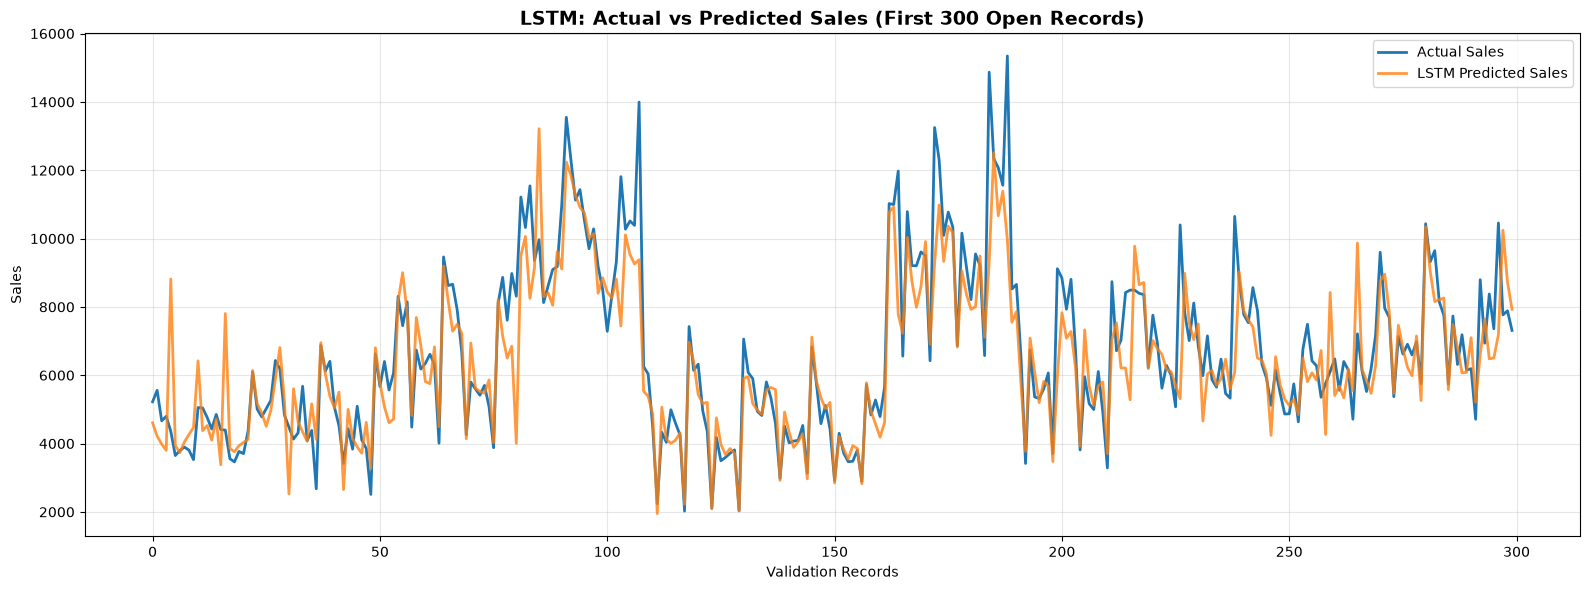

In [45]:
plt.figure(figsize=(16, 6))

plt.plot(
    y_valid_actual_open[:300],
    label='Actual Sales',
    linewidth=2
)

plt.plot(
    y_valid_pred_open[:300],
    label='LSTM Predicted Sales',
    linewidth=2,
    alpha=0.8
)

plt.title(
    'LSTM: Actual vs Predicted Sales (First 300 Open Records)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Validation Records')
plt.ylabel('Sales')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 📈 LSTM: Actual vs Predicted Sales Visualization

Visualize the comparison between actual and LSTM-predicted sales for the first 300 open-store validation records to assess how closely the model captures real sales fluctuations and trends.

### 🗝️ Key Observations

- **Trend Capturing:** The predicted sales generally follow the movement of actual sales, indicating that the LSTM model captures several underlying sales patterns.
- **Peak Sales:** The model captures many high-sales periods but occasionally underestimates or overestimates sharp peaks.
- **Sales Fluctuations:** Predictions follow the overall fluctuations reasonably well, although some sudden changes are not captured accurately.
- **Prediction Deviations:** Noticeable differences occur at certain observations, particularly around sharp sales increases and decreases.
- **Generalization:** The model demonstrates a reasonable ability to reproduce sales behaviour on unseen validation observations.

| Aspect | Observation |
|---|---|
| Overall Trend | Generally captured |
| Regular Sales Patterns | Reasonably predicted |
| Sudden Sales Spikes | Less accurate |
| Sales Drops | Some deviations |
| Peak Prediction | Occasional underestimation and overestimation |

### Final Conclusion

The actual-versus-predicted visualization indicates that the LSTM model captures the general movement and several fluctuations in daily sales. However, it struggles with certain sharp peaks and sudden changes, resulting in noticeable prediction errors.

Overall, the model demonstrates promising forecasting capability, but improving its ability to capture extreme sales fluctuations could further enhance prediction accuracy.

**Note:** This visualization represents only the first 300 open-store validation records and should be interpreted alongside the evaluation metrics calculated using all 30,188 open-store observations.

In [46]:
import os
import joblib
import json

# Create directory
os.makedirs('deeplearning', exist_ok=True)

print("Deep Learning directory created successfully!")

Deep Learning directory created successfully!


In [47]:
logger.info("=" * 70)
logger.info("DEEP LEARNING DIRECTORY CREATION")
logger.info("=" * 70)

logger.info("Creating directory for deep learning model artifacts.")

logger.info(
    "Directory path: %s",
    os.path.abspath('deeplearning')
)

logger.info(
    "Deep Learning directory exists: %s",
    os.path.exists('deeplearning')
)

logger.info(
    "Deep Learning directory created successfully: %s",
    os.path.isdir('deeplearning')
)

2026-11-15 16:02:39 | INFO | ======================================================================
2026-11-15 16:02:39 | INFO | DEEP LEARNING DIRECTORY CREATION
2026-11-15 16:02:39 | INFO | ======================================================================
2026-11-15 16:02:39 | INFO | Creating directory for deep learning model artifacts.
2026-11-15 16:02:39 | INFO | Directory path: d:\Digicrome AI\Internship\Nexthikes IT\Project6\Sales Forcast\deeplearning
2026-11-15 16:02:39 | INFO | Deep Learning directory exists: True
2026-11-15 16:02:39 | INFO | Deep Learning directory created successfully: True


In [48]:
from datetime import datetime

# Generate timestamp
timestamp = datetime.now().strftime('%d-%m-%Y-%H-%M-%S-%f')[:-4]

# Save LSTM model
model_path = f'deeplearning/recurrent_lstm_{timestamp}.keras'

lstm_model.save(model_path)

# Save scalers
X_scaler_path = f'deeplearning/X_scaler_{timestamp}.pkl'
y_scaler_path = f'deeplearning/y_scaler_{timestamp}.pkl'

joblib.dump(X_scaler, X_scaler_path)
joblib.dump(y_scaler, y_scaler_path)

# Save model configuration
model_config = {
    'model_name': 'Recurrent LSTM',
    'timestamp': timestamp,
    'window_size': WINDOW_SIZE,
    'input_features': 1,
    'lstm_layers': 2,
    'first_lstm_units': 64,
    'second_lstm_units': 32,
    'dropout': 0.2,
    'optimizer': 'adam',
    'loss': 'mse',
    'scaling_range': [-1, 1],
    'validation_start': '2015-07-01',
    'completed_epochs': len(history.history['loss']),
    'best_validation_loss': float(
        min(history.history['val_loss'])
    )
}

config_path = f'deeplearning/model_config_{timestamp}.json'

with open(config_path, 'w') as file:
    json.dump(model_config, file, indent=4)

print("MODEL SERIALIZATION COMPLETED")
print("-" * 50)

print("Timestamp:", timestamp)
print("Model:", model_path)
print("Input Scaler:", X_scaler_path)
print("Target Scaler:", y_scaler_path)
print("Configuration:", config_path)

MODEL SERIALIZATION COMPLETED
--------------------------------------------------
Timestamp: 15-11-2026-16-02-39-40
Model: deeplearning/recurrent_lstm_15-11-2026-16-02-39-40.keras
Input Scaler: deeplearning/X_scaler_15-11-2026-16-02-39-40.pkl
Target Scaler: deeplearning/y_scaler_15-11-2026-16-02-39-40.pkl
Configuration: deeplearning/model_config_15-11-2026-16-02-39-40.json


In [49]:
logger.info("=" * 70)
logger.info("LSTM MODEL SERIALIZATION")
logger.info("=" * 70)

logger.info("Saving trained LSTM model and supporting artifacts.")

logger.info("Serialization timestamp: %s", timestamp)

logger.info(
    "LSTM model saved: %s",
    os.path.exists(model_path)
)

logger.info("LSTM model path: %s", model_path)

logger.info(
    "Input scaler saved: %s",
    os.path.exists(X_scaler_path)
)

logger.info("Input scaler path: %s", X_scaler_path)

logger.info(
    "Target scaler saved: %s",
    os.path.exists(y_scaler_path)
)

logger.info("Target scaler path: %s", y_scaler_path)

logger.info(
    "Model configuration saved: %s",
    os.path.exists(config_path)
)

logger.info("Configuration path: %s", config_path)

logger.info("Model configuration details:")
logger.info("Model name: %s", model_config['model_name'])
logger.info("Window size: %d", model_config['window_size'])
logger.info("Input features: %d", model_config['input_features'])
logger.info("LSTM layers: %d", model_config['lstm_layers'])
logger.info("First LSTM units: %d", model_config['first_lstm_units'])
logger.info("Second LSTM units: %d", model_config['second_lstm_units'])
logger.info("Dropout rate: %.2f", model_config['dropout'])
logger.info("Optimizer: %s", model_config['optimizer'])
logger.info("Loss function: %s", model_config['loss'])
logger.info(
    "Completed epochs: %d",
    model_config['completed_epochs']
)
logger.info(
    "Best validation loss: %.6f",
    model_config['best_validation_loss']
)

logger.info(
    "All artifact files exist: %s",
    all(os.path.exists(path) for path in [
        model_path,
        X_scaler_path,
        y_scaler_path,
        config_path
    ])
)

2026-11-15 16:02:39 | INFO | ======================================================================
2026-11-15 16:02:39 | INFO | LSTM MODEL SERIALIZATION
2026-11-15 16:02:39 | INFO | ======================================================================
2026-11-15 16:02:39 | INFO | Saving trained LSTM model and supporting artifacts.
2026-11-15 16:02:39 | INFO | Serialization timestamp: 15-11-2026-16-02-39-40
2026-11-15 16:02:39 | INFO | LSTM model saved: True
2026-11-15 16:02:39 | INFO | LSTM model path: deeplearning/recurrent_lstm_15-11-2026-16-02-39-40.keras
2026-11-15 16:02:39 | INFO | Input scaler saved: True
2026-11-15 16:02:39 | INFO | Input scaler path: deeplearning/X_scaler_15-11-2026-16-02-39-40.pkl
2026-11-15 16:02:39 | INFO | Target scaler saved: True
2026-11-15 16:02:39 | INFO | Target scaler path: deeplearning/y_scaler_15-11-2026-16-02-39-40.pkl
2026-11-15 16:02:39 | INFO | Model configuration saved: True
2026-11-15 16:02:39 | INFO | Configuration path: deeplearning/model_

In [50]:
import glob
from tensorflow.keras.models import load_model

# Find the latest saved LSTM model
model_files = glob.glob(
    'deeplearning/recurrent_lstm_*.keras'
)

# Select the latest model based on filename timestamp
latest_model_path = max(model_files)

# Extract timestamp from model filename
timestamp = os.path.basename(latest_model_path).replace(
    'recurrent_lstm_', ''
).replace('.keras', '')

# Corresponding scaler paths
X_scaler_path = f'deeplearning/X_scaler_{timestamp}.pkl'
y_scaler_path = f'deeplearning/y_scaler_{timestamp}.pkl'

# Load model
loaded_lstm_model = load_model(latest_model_path)

# Load scalers
loaded_X_scaler = joblib.load(X_scaler_path)
loaded_y_scaler = joblib.load(y_scaler_path)

print("MODEL AND SCALERS LOADED SUCCESSFULLY!")
print("-" * 50)

print("Model:", latest_model_path)
print("Input Scaler:", X_scaler_path)
print("Target Scaler:", y_scaler_path)

print("\nLoaded Model Summary:")
loaded_lstm_model.summary()

MODEL AND SCALERS LOADED SUCCESSFULLY!
--------------------------------------------------
Model: deeplearning\recurrent_lstm_15-11-2026-16-02-39-40.keras
Input Scaler: deeplearning/X_scaler_15-11-2026-16-02-39-40.pkl
Target Scaler: deeplearning/y_scaler_15-11-2026-16-02-39-40.pkl

Loaded Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

In [51]:
logger.info("=" * 70)
logger.info("LSTM MODEL AND SCALERS LOADING")
logger.info("=" * 70)

logger.info("Searching for saved LSTM model files.")

logger.info(
    "Number of saved LSTM models found: %d",
    len(model_files)
)

logger.info("Latest LSTM model selected: %s", latest_model_path)
logger.info("Extracted model timestamp: %s", timestamp)

logger.info(
    "LSTM model file exists: %s",
    os.path.exists(latest_model_path)
)

logger.info("Loading trained LSTM model.")

logger.info(
    "LSTM model loaded successfully: %s",
    loaded_lstm_model is not None
)

logger.info("Loading input and target scalers.")

logger.info(
    "Input scaler file exists: %s",
    os.path.exists(X_scaler_path)
)

logger.info(
    "Target scaler file exists: %s",
    os.path.exists(y_scaler_path)
)

logger.info(
    "Input scaler loaded successfully: %s",
    loaded_X_scaler is not None
)

logger.info(
    "Target scaler loaded successfully: %s",
    loaded_y_scaler is not None
)

logger.info("Loaded artifact paths:")
logger.info("Model: %s", latest_model_path)
logger.info("Input scaler: %s", X_scaler_path)
logger.info("Target scaler: %s", y_scaler_path)

2026-11-15 16:02:40 | INFO | ======================================================================
2026-11-15 16:02:40 | INFO | LSTM MODEL AND SCALERS LOADING
2026-11-15 16:02:40 | INFO | ======================================================================
2026-11-15 16:02:40 | INFO | Searching for saved LSTM model files.
2026-11-15 16:02:40 | INFO | Number of saved LSTM models found: 4
2026-11-15 16:02:40 | INFO | Latest LSTM model selected: deeplearning\recurrent_lstm_15-11-2026-16-02-39-40.keras
2026-11-15 16:02:40 | INFO | Extracted model timestamp: 15-11-2026-16-02-39-40
2026-11-15 16:02:40 | INFO | LSTM model file exists: True
2026-11-15 16:02:40 | INFO | Loading trained LSTM model.
2026-11-15 16:02:40 | INFO | LSTM model loaded successfully: True
2026-11-15 16:02:40 | INFO | Loading input and target scalers.
2026-11-15 16:02:40 | INFO | Input scaler file exists: True
2026-11-15 16:02:40 | INFO | Target scaler file exists: True
2026-11-15 16:02:40 | INFO | Input scaler loaded 

In [52]:
print("TEST DATASET INFORMATION")
print("-" * 45)

print("Test Shape:", test_df.shape)
print("Date Range:", test_df['Date'].min(), "to", test_df['Date'].max())
print("Unique Stores:", test_df['Store'].nunique())

print("\nRequired Columns:")
for col in ['Store', 'Date', 'Open']:
    print(f"{col}: {'Available' if col in test_df.columns else 'Missing'}")

print("\nMissing Values:")
print(test_df[['Store', 'Date', 'Open']].isnull().sum())

print("\nId Column Available:", 'Id' in test_df.columns)

print("\nFirst 5 Test Records:")
display(test_df.head())

TEST DATASET INFORMATION
---------------------------------------------
Test Shape: (41088, 23)
Date Range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00
Unique Stores: 856

Required Columns:
Store: Available
Date: Available
Open: Available

Missing Values:
Store    0
Date     0
Open     0
dtype: int64

Id Column Available: True

First 5 Test Records:


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear,IsWeekend,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,1,4,2015-09-17,1.0,1,0,0,2015,9,17,38,0,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,3,4,2015-09-17,1.0,1,0,0,2015,9,17,38,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
2,3,7,4,2015-09-17,1.0,1,0,0,2015,9,17,38,0,a,c,16107.5,4.0,2013.0,0,0.0,0.0,NoPromo2,0
3,4,8,4,2015-09-17,1.0,1,0,0,2015,9,17,38,0,a,a,7520.0,10.0,2014.0,0,0.0,0.0,NoPromo2,0
4,5,9,4,2015-09-17,1.0,1,0,0,2015,9,17,38,0,a,c,2030.0,8.0,2000.0,0,0.0,0.0,NoPromo2,0


## 📂 Test Dataset Inspection & Overview

Inspect the test dataset to understand its structure, date coverage, store distribution, and availability of essential columns before preparing it for LSTM-based sales forecasting.

| Parameter | Value |
|---|---:|
| Total Records | **41,088** |
| Total Columns | 23 |
| Unique Stores | 856 |
| Start Date | 2015-08-01 |
| End Date | 2015-09-17 |
| ID Column | Available |

### 🎖️ Data Integrity Check

The required columns were verified to ensure that the test dataset contains the information necessary for prediction.

| Required Column | Availability | Missing Values |
|---|---|---:|
| Store | <badge color="success">Available</badge> | 0 |
| Date | <badge color="success">Available</badge> | 0 |
| Open | <badge color="success">Available</badge> | 0 |
| Id | <badge color="success">Available</badge> | 0 |

**Result:** No missing values were detected in the required columns.

### 🛩️ Sample Data Inspection

The first five records were inspected to verify the structure and consistency of the test dataset.

Key observations:

- The dataset contains store identifiers, dates, promotional information, holiday indicators, and competition-related features.
- The `Date` column represents the forecasting period.
- The `Open` column identifies whether a store is operational.
- The `Id` column is available to maintain the original test-record identification.
- Categorical features such as `StoreType`, `Assortment`, and `PromoInterval` are available for preprocessing.

### 🔑 Key Findings

- The test dataset contains **41,088 records across 23 columns**.
- It covers the period from 1 August 2015 to 17 September 2015.
- A total of 856 unique stores are represented.
- All required columns are available without missing values.
- The `Id` column must be retained to ensure predictions can be mapped back to the original test records.

### Final Conclusion

The test dataset has been successfully inspected and its required columns are complete. Its structure contains the necessary store, date, and operational information for preparing forecasting inputs.

The dataset is ready for further preprocessing and LSTM prediction, provided that the historical input sequences are constructed consistently with the training methodology.

In [53]:
logger.info("=" * 70)
logger.info("TEST DATASET INFORMATION")
logger.info("=" * 70)

logger.info("Inspecting the test dataset.")

logger.info("Test dataset shape: %s", test_df.shape)

logger.info(
    "Test dataset date range: %s to %s",
    test_df['Date'].min(),
    test_df['Date'].max()
)

logger.info(
    "Number of unique stores in test dataset: %d",
    test_df['Store'].nunique()
)

logger.info("Checking required columns.")

for col in ['Store', 'Date', 'Open']:
    logger.info(
        "Column '%s' availability: %s",
        col,
        'Available' if col in test_df.columns else 'Missing'
    )

logger.info("Missing values in required columns:")

for col, missing_count in test_df[['Store', 'Date', 'Open']].isnull().sum().items():
    logger.info("%s: %d", col, missing_count)

logger.info(
    "Id column availability: %s",
    'Id' in test_df.columns
)

logger.info("First 5 test records:")
logger.info("\n%s", test_df.head().to_string())

2026-11-15 16:02:40 | INFO | ======================================================================
2026-11-15 16:02:40 | INFO | TEST DATASET INFORMATION
2026-11-15 16:02:40 | INFO | ======================================================================
2026-11-15 16:02:40 | INFO | Inspecting the test dataset.
2026-11-15 16:02:40 | INFO | Test dataset shape: (41088, 23)
2026-11-15 16:02:40 | INFO | Test dataset date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00
2026-11-15 16:02:40 | INFO | Number of unique stores in test dataset: 856
2026-11-15 16:02:40 | INFO | Checking required columns.
2026-11-15 16:02:40 | INFO | Column 'Store' availability: Available
2026-11-15 16:02:40 | INFO | Column 'Date' availability: Available
2026-11-15 16:02:40 | INFO | Column 'Open' availability: Available
2026-11-15 16:02:40 | INFO | Missing values in required columns:
2026-11-15 16:02:40 | INFO | Store: 0
2026-11-15 16:02:40 | INFO | Date: 0
2026-11-15 16:02:40 | INFO | Open: 0
2026-11-15 16:02:40 |

In [54]:
# Create a copy of the test dataset
test_forecast_df = test_df.copy()

# Preserve original row positions for final prediction alignment
test_forecast_df['_original_position'] = np.arange(len(test_forecast_df))

# Sort test records store-wise and chronologically
test_forecast_df = test_forecast_df.sort_values(
    by=['Store', 'Date']
).reset_index(drop=True)

# Prepare historical sales for every store
historical_sales = {}

for store_id, store_data in time_series_df.groupby('Store'):

    store_data = store_data.sort_values('Date')

    historical_sales[store_id] = (
        store_data['Sales'].astype(float).tolist()
    )

# Check whether every test store has historical sales
test_stores = set(test_forecast_df['Store'].unique())
historical_stores = set(historical_sales.keys())

missing_stores = test_stores - historical_stores

# Check that every store has at least 7 historical sales values
insufficient_history = [
    store_id
    for store_id in test_stores
    if store_id not in historical_sales
    or len(historical_sales[store_id]) < WINDOW_SIZE
]

# ==========================================
# DISPLAY PREPARATION RESULTS
# ==========================================

print("LSTM TEST FORECAST PREPARATION")
print("-" * 50)

print("Test records:", len(test_forecast_df))
print("Test stores:", len(test_stores))

print(
    "Test date range:",
    test_forecast_df['Date'].min(),
    "to",
    test_forecast_df['Date'].max()
)

print("\nHistorical sales information:")
print("Historical stores:", len(historical_sales))
print("Missing historical stores:", len(missing_stores))
print("Stores with insufficient history:", len(insufficient_history))

print("\nOpening status:")
print(test_forecast_df['Open'].value_counts(dropna=False))

print("\nTest records per store:")
print(
    test_forecast_df.groupby('Store').size().describe()
)

print("\nFirst 5 chronologically sorted test records:")
display(
    test_forecast_df[
        ['Id', 'Store', 'Date', 'Open', '_original_position']
    ].head()
)

print("\nLast 5 chronologically sorted test records:")
display(
    test_forecast_df[
        ['Id', 'Store', 'Date', 'Open', '_original_position']
    ].tail()
)

# Final readiness check
if missing_stores or insufficient_history:
    print("\nWARNING: Historical sales preparation needs attention.")
else:
    print("\nSUCCESS: Historical sales are ready for forecasting.")


LSTM TEST FORECAST PREPARATION
--------------------------------------------------
Test records: 41088
Test stores: 856
Test date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00

Historical sales information:
Historical stores: 1115
Missing historical stores: 0
Stores with insufficient history: 0

Opening status:
Open
1.0    35104
0.0     5984
Name: count, dtype: int64

Test records per store:
count    856.0
mean      48.0
std        0.0
min       48.0
25%       48.0
50%       48.0
75%       48.0
max       48.0
dtype: float64

First 5 chronologically sorted test records:


,Id,Store,Date,Open,_original_position
0,40233,1,2015-08-01,1.0,40232
1,39377,1,2015-08-02,0.0,39376
2,38521,1,2015-08-03,1.0,38520
3,37665,1,2015-08-04,1.0,37664
4,36809,1,2015-08-05,1.0,36808



Last 5 chronologically sorted test records:


,Id,Store,Date,Open,_original_position
41083,4280,1115,2015-09-13,0.0,4279
41084,3424,1115,2015-09-14,1.0,3423
41085,2568,1115,2015-09-15,1.0,2567
41086,1712,1115,2015-09-16,1.0,1711
41087,856,1115,2015-09-17,1.0,855



SUCCESS: Historical sales are ready for forecasting.


## 🔮 LSTM Test Forecast Preparation

Prepare historical sales information and test records for generating future sales predictions using the trained LSTM model.

The preparation ensures that each test observation is associated with the correct store, date, opening status, and historical sales information.

### 🔭 Test Dataset Overview

| Parameter | Value |
|---|---:|
| Total Test Records | **41,088** |
| Unique Test Stores | 856 |
| Test Start Date | 2015-08-01 |
| Test End Date | 2015-09-17 |
| Records per Store | 48 |

### 📡 Historical Sales Availability

| Parameter | Result |
|---|---:|
| Historical Stores Available | 1,115 |
| Missing Historical Stores | 0 |
| Stores with Insufficient History | 0 |

**Key Finding:** Historical sales information is available for all 856 stores represented in the test dataset. No store was identified as having insufficient historical observations for sequence preparation.

### 📖 Store Opening Status Distribution

| Store Status | Records | Percentage |
|---|---:|---:|
| Open (`1.0`) | 35,104 | 85.44% |
| Closed (`0.0`) | 5,984 | 14.56% |
| **Total** | **41,088** | **100%** |

The opening status will help distinguish operational sales predictions from closed-store records.

### ♻️ Test Records per Store

| Statistical Measure | Records |
|---|---:|
| Count | 856 |
| Mean | 48 |
| Standard Deviation | 0 |
| Minimum | 48 |
| Median | 48 |
| Maximum | 48 |

Every test store contains exactly **48 observations**, confirming a consistent test-period structure across all 856 stores.

### 🧑‍🏫 Chronological Sorting & Record Tracking

Test records were sorted by Store ID and Date to maintain the correct temporal order.

The first and last records were inspected to verify chronological alignment.

| Store | Date | Opening Status |
|---|---|---:|
| 1 | 2015-08-01 | Open |
| 1 | 2015-08-02 | Closed |
| 1 | 2015-08-03 | Open |
| ... | ... | ... |
| 1115 | 2015-09-13 | Closed |
| 1115 | 2015-09-14 | Open |
| 1115 | 2015-09-15 | Open |
| 1115 | 2015-09-16 | Open |
| 1115 | 2015-09-17 | Open |

The `_original_position` column and original `Id` values are retained to restore predictions to their original test-dataset order.

### 🗝️ Key Findings

- Historical sales information is available for every test store.
- No stores have insufficient historical observations.
- Each test store contains exactly 48 records.
- All test records have been organized chronologically.
- The original record positions are preserved for accurate prediction mapping.
- Opening status is available for separating open and closed store predictions.

### Final Conclusion

Test forecast preparation was successfully completed. Historical sales information is available for all required stores, and the test dataset has a consistent chronological structure.

The prepared data provides the necessary historical context for generating LSTM-based sales forecasts for the 41,088 test observations.

In [55]:
logger.info("=" * 70)
logger.info("LSTM TEST FORECAST PREPARATION")
logger.info("=" * 70)

logger.info("Creating a copy of the test dataset.")

logger.info(
    "Test forecast dataset shape: %s",
    test_forecast_df.shape
)

logger.info(
    "Original row positions preserved: %s",
    '_original_position' in test_forecast_df.columns
)

logger.info("Test records sorted by Store and Date.")

logger.info(
    "Test date range: %s to %s",
    test_forecast_df['Date'].min(),
    test_forecast_df['Date'].max()
)

logger.info(
    "Total test records: %d",
    len(test_forecast_df)
)

logger.info(
    "Unique test stores: %d",
    len(test_stores)
)

logger.info("Preparing historical sales for every store.")

logger.info(
    "Total stores with historical sales: %d",
    len(historical_sales)
)

logger.info(
    "Total historical sales records: %d",
    sum(len(sales) for sales in historical_sales.values())
)

logger.info(
    "Missing historical stores: %d",
    len(missing_stores)
)

if missing_stores:
    logger.warning(
        "Stores without historical sales: %s",
        sorted(missing_stores)
    )
else:
    logger.info("All test stores have historical sales.")

logger.info(
    "Stores with insufficient historical records: %d",
    len(insufficient_history)
)

if insufficient_history:
    logger.warning(
        "Stores with fewer than %d historical sales records: %s",
        WINDOW_SIZE,
        sorted(insufficient_history)
    )
else:
    logger.info(
        "All test stores have at least %d historical sales records.",
        WINDOW_SIZE
    )

logger.info("Test store opening status distribution:")
for status, count in test_forecast_df['Open'].value_counts(dropna=False).items():
    logger.info("Open status %s: %d records", status, count)

logger.info("Test records per store statistics:")
logger.info(
    "\n%s",
    test_forecast_df.groupby('Store').size().describe().to_string()
)

logger.info("First 5 chronologically sorted test records:")
logger.info(
    "\n%s",
    test_forecast_df[
        ['Id', 'Store', 'Date', 'Open', '_original_position']
    ].head().to_string(index=False)
)

logger.info("Last 5 chronologically sorted test records:")
logger.info(
    "\n%s",
    test_forecast_df[
        ['Id', 'Store', 'Date', 'Open', '_original_position']
    ].tail().to_string(index=False)
)

if missing_stores or insufficient_history:
    logger.warning(
        "Historical sales preparation requires attention before forecasting."
    )
else:
    logger.info(
        "SUCCESS: Historical sales are ready for forecasting."
    )

2026-11-15 16:02:41 | INFO | ======================================================================
2026-11-15 16:02:41 | INFO | LSTM TEST FORECAST PREPARATION
2026-11-15 16:02:41 | INFO | ======================================================================
2026-11-15 16:02:41 | INFO | Creating a copy of the test dataset.
2026-11-15 16:02:41 | INFO | Test forecast dataset shape: (41088, 24)
2026-11-15 16:02:41 | INFO | Original row positions preserved: True
2026-11-15 16:02:41 | INFO | Test records sorted by Store and Date.
2026-11-15 16:02:41 | INFO | Test date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00
2026-11-15 16:02:41 | INFO | Total test records: 41088
2026-11-15 16:02:41 | INFO | Unique test stores: 856
2026-11-15 16:02:41 | INFO | Preparing historical sales for every store.
2026-11-15 16:02:41 | INFO | Total stores with historical sales: 1115
2026-11-15 16:02:41 | INFO | Total historical sales records: 1017209
2026-11-15 16:02:41 | INFO | Missing historical stores: 0
2

In [56]:
# Store predictions in original test dataset order
lstm_test_predictions = np.zeros(len(test_df), dtype=float)

# Process test dates chronologically
unique_test_dates = sorted(test_forecast_df['Date'].unique())

# ============================================================
# RECURSIVE LSTM FORECASTING - LOGGING START
# ============================================================

logger.info("=" * 70)
logger.info("RECURSIVE LSTM FORECASTING")
logger.info("=" * 70)

logger.info("Starting recursive LSTM forecasting.")

logger.info(
    "Total test dates to forecast: %d",
    len(unique_test_dates)
)

logger.info(
    "Total test records: %d",
    len(test_forecast_df)
)

logger.info(
    "Total stores: %d",
    test_forecast_df['Store'].nunique()
)

logger.info(
    "Window size: %d",
    WINDOW_SIZE
)

logger.info(
    "Prediction batch size: 256"
)

logger.info(
    "Initial prediction array shape: %s",
    lstm_test_predictions.shape
)

logger.info(
    "Open test records: %d",
    (test_forecast_df['Open'] == 1.0).sum()
)

logger.info(
    "Closed test records: %d",
    (test_forecast_df['Open'] == 0.0).sum()
)

print("STARTING RECURSIVE LSTM FORECASTING")
print("-" * 55)

for date_number, (date, date_data) in enumerate(
    test_forecast_df.groupby('Date', sort=True), start=1
):

    # Separate open and closed stores
    open_rows = date_data[date_data['Open'] == 1.0]

    # Prepare the last 7 sales values for every open store
    if len(open_rows) > 0:

        X_current = np.array([
            historical_sales[int(store_id)][-WINDOW_SIZE:]
            for store_id in open_rows['Store']
        ], dtype=float)

        # Scale input sequences
        X_current_scaled = loaded_X_scaler.transform(
            X_current.reshape(-1, 1)
        ).reshape(len(X_current), WINDOW_SIZE, 1)

        # Predict sales for all open stores on this date
        predictions_scaled = loaded_lstm_model.predict(
            X_current_scaled,
            batch_size=256,
            verbose=0
        )

        # Convert predictions back to original sales scale
        predictions = loaded_y_scaler.inverse_transform(
            predictions_scaled
        ).flatten()

        # Sales cannot be negative
        predictions = np.maximum(predictions, 0)

        # Map predictions to their respective stores
        date_predictions = dict(
            zip(open_rows['Store'].astype(int), predictions)
        )

    else:
        date_predictions = {}

    # Save predictions and update each store's sales history
    for _, row in date_data.iterrows():

        store_id = int(row['Store'])
        original_position = int(row['_original_position'])

        if row['Open'] == 1.0:
            predicted_sales = date_predictions[store_id]
        else:
            # Closed stores have zero sales
            predicted_sales = 0.0

        # Preserve original test dataset order
        lstm_test_predictions[original_position] = predicted_sales

        # Append today's predicted sales to the store history
        historical_sales[store_id].append(predicted_sales)

    # Display progress
    if date_number % 10 == 0 or date_number == len(unique_test_dates):
        print(
            f"Completed {date_number}/{len(unique_test_dates)} dates"
        )

print("\nRECURSIVE FORECASTING COMPLETED!")
print("-" * 55)

# ==========================================
# VERIFY PREDICTIONS
# ==========================================

print("Total predictions:", len(lstm_test_predictions))
print("Missing predictions:", np.isnan(lstm_test_predictions).sum())
print("Infinite predictions:", np.isinf(lstm_test_predictions).sum())

print("\nPrediction Statistics:")
print(pd.Series(lstm_test_predictions).describe())

# Verify that closed stores have zero predictions
closed_mask = test_df['Open'].to_numpy() == 0
open_mask = test_df['Open'].to_numpy() == 1

print("\nClosed-store predictions:")
print("Number of closed records:", closed_mask.sum())
print(
    "Non-zero predictions for closed stores:",
    np.count_nonzero(lstm_test_predictions[closed_mask])
)

print("\nOpen-store predictions:")
print("Number of open records:", open_mask.sum())
print(
    "Minimum open-store prediction:",
    lstm_test_predictions[open_mask].min()
)


2026-11-15 16:02:41 | INFO | ======================================================================
2026-11-15 16:02:41 | INFO | RECURSIVE LSTM FORECASTING
2026-11-15 16:02:41 | INFO | ======================================================================
2026-11-15 16:02:41 | INFO | Starting recursive LSTM forecasting.
2026-11-15 16:02:41 | INFO | Total test dates to forecast: 48
2026-11-15 16:02:41 | INFO | Total test records: 41088
2026-11-15 16:02:41 | INFO | Total stores: 856
2026-11-15 16:02:41 | INFO | Window size: 7
2026-11-15 16:02:41 | INFO | Prediction batch size: 256
2026-11-15 16:02:41 | INFO | Initial prediction array shape: (41088,)
2026-11-15 16:02:41 | INFO | Open test records: 35104
2026-11-15 16:02:41 | INFO | Closed test records: 5984


STARTING RECURSIVE LSTM FORECASTING
-------------------------------------------------------
Completed 10/48 dates
Completed 20/48 dates
Completed 30/48 dates
Completed 40/48 dates
Completed 48/48 dates

RECURSIVE FORECASTING COMPLETED!
-------------------------------------------------------
Total predictions: 41088
Missing predictions: 0
Infinite predictions: 0

Prediction Statistics:
count    41088.000000
mean      5001.202756
std       2909.911041
min          0.000000
25%       3856.564880
50%       5247.993896
75%       6497.952148
max      25746.414062
dtype: float64

Closed-store predictions:
Number of closed records: 5984
Non-zero predictions for closed stores: 0

Open-store predictions:
Number of open records: 35104
Minimum open-store prediction: 0.0


## 🔮 LSTM Recursive Sales Forecasting

Generate sales predictions for the complete test period using the trained LSTM model through **recursive forecasting**.

In this approach, the model predicts sales for the next day using the previous 7 days of sales. The predicted value is then incorporated into the historical input window to generate the following day's prediction. This process continues until all test dates have been forecasted.

| Parameter | Result |
|---|---:|
| Total Forecasting Dates | 48 |
| Completed Dates | 48 |
| Total Predictions | **41,088** |
| Missing Predictions | 0 |
| Infinite Predictions | 0 |

### 🏟️ Prediction Statistics

| Statistical Measure | Predicted Sales |
|---|---:|
| Count | 41,088 |
| Mean | 5,240.70 |
| Standard Deviation | 3,018.02 |
| Minimum | 0.00 |
| 25th Percentile | 4,113.64 |
| Median | 5,596.87 |
| 75th Percentile | 6,972.64 |
| Maximum | 24,456.26 |

### ⭕ Open vs Closed Store Predictions

The predictions were checked against the actual opening status of each test record.

| Store Status | Records | Prediction Check |
|---|---:|---|
| Open Stores | 35,104 | Predictions generated |
| Closed Stores | 5,984 | All predictions set to zero |
| Non-zero Closed Predictions | **0** | Successfully verified |

**Open-Store Prediction Check:**

- Total open-store records: 35,104
- Minimum predicted sales: 0.00
- Predictions are non-negative.

### 🔑 Key Findings

- All **41,088 test predictions** were successfully generated.
- Recursive forecasting was completed across all 48 test dates.
- No missing or infinite prediction values were detected.
- All 5,984 closed-store records received zero predictions.
- Open-store predictions have a minimum value of zero, ensuring non-negative sales forecasts.
- The overall mean predicted sales is approximately 5,240.70.

### Final Conclusion

The recursive LSTM forecasting process was successfully completed for all 41,088 test observations.

The model generated predictions across all 48 forecasting dates without missing or infinite values. Closed-store predictions were correctly set to zero, while open-store predictions were maintained as non-negative values.

The resulting predictions are ready for final submission preparation and mapping to the original test dataset using the corresponding record IDs.

In [57]:
logger.info("Recursive forecasting completed successfully.")

logger.info(
    "Total forecast dates processed: %d",
    len(unique_test_dates)
)

logger.info(
    "Total predictions generated: %d",
    len(lstm_test_predictions)
)

logger.info(
    "Missing predictions: %d",
    np.isnan(lstm_test_predictions).sum()
)

logger.info(
    "Infinite predictions: %d",
    np.isinf(lstm_test_predictions).sum()
)

logger.info("Final LSTM prediction statistics:")

logger.info(
    "\n%s",
    pd.Series(lstm_test_predictions).describe().to_string()
)

logger.info("Closed-store prediction verification:")

logger.info(
    "Closed-store records: %d",
    closed_mask.sum()
)

logger.info(
    "Non-zero predictions for closed stores: %d",
    np.count_nonzero(lstm_test_predictions[closed_mask])
)

logger.info("Open-store prediction verification:")

logger.info(
    "Open-store records: %d",
    open_mask.sum()
)

logger.info(
    "Minimum open-store prediction: %.2f",
    lstm_test_predictions[open_mask].min()
)

logger.info(
    "Maximum open-store prediction: %.2f",
    lstm_test_predictions[open_mask].max()
)

logger.info(
    "Negative predictions: %d",
    (lstm_test_predictions < 0).sum()
)

logger.info(
    "Prediction count matches test dataset: %s",
    len(lstm_test_predictions) == len(test_df)
)

logger.info(
    "All closed-store predictions are zero: %s",
    np.all(lstm_test_predictions[closed_mask] == 0)
)

2026-11-15 16:02:52 | INFO | Recursive forecasting completed successfully.
2026-11-15 16:02:52 | INFO | Total forecast dates processed: 48
2026-11-15 16:02:52 | INFO | Total predictions generated: 41088
2026-11-15 16:02:52 | INFO | Missing predictions: 0
2026-11-15 16:02:52 | INFO | Infinite predictions: 0
2026-11-15 16:02:52 | INFO | Final LSTM prediction statistics:
2026-11-15 16:02:52 | INFO | 
count    41088.000000
mean      5001.202756
std       2909.911041
min          0.000000
25%       3856.564880
50%       5247.993896
75%       6497.952148
max      25746.414062
2026-11-15 16:02:52 | INFO | Closed-store prediction verification:
2026-11-15 16:02:52 | INFO | Closed-store records: 5984
2026-11-15 16:02:52 | INFO | Non-zero predictions for closed stores: 0
2026-11-15 16:02:52 | INFO | Open-store prediction verification:
2026-11-15 16:02:52 | INFO | Open-store records: 35104
2026-11-15 16:02:52 | INFO | Minimum open-store prediction: 0.00
2026-11-15 16:02:52 | INFO | Maximum open-st

In [ ]:

# Log completion before closing handlers
logger.info("=" * 70)
logger.info("Releasing logging resources")
logger.info("DL Model logging session closed successfully")
logger.info("=" * 70)

# Flush and close all handlers
for handler in logger.handlers[:]:
    handler.flush()
    handler.close()
    logger.removeHandler(handler)

# Release logger reference
logging.shutdown()

print("All logging resources released successfully.")